# EVALUACIÓN DIAGNÓSTICA DE LA SEPARABILIDAD ESPACIAL EN EL RIFT DE BAJA CALIFORNIA: ALCANCES Y LIMITACIONES DEL APRENDIZAJE AUTOMÁTICO REGIONAL

**Autor:** Rubén Rivera García  
**Programa:** Maestría en Ciencias en Ciencias de la Computación | CICESE  
**Asignatura:** Ciencia de Datos (Semestre 2026-3)  
**Profesor:** Dr. Irvin Hussein López Nava 
**Fecha:** Noviembre de 2026  
**Repositorio de GitHub:** [https://github.com/rubenriv2111-beep/ICD-2026](https://github.com/rubenriv2111-beep/ICD-2026)  

---


> **Nota de Reproducibilidad y Arquitectura Modular del Repositorio:**
> * **Notebook Principal (`Proyecto_Ciencia_De_Datos_Geotermia.ipynb`):** Ejecuta de principio a fin el flujo analítico completo bajo el **Protocolo A** (partición estratificada 70/15/15), comparación pareada de 5 funciones de activación en redes neuronales profundas (PyTorch con BatchNorm), curvas de aprendizaje, matrices de confusión, curvas ROC y Precision-Recall logarítmicas, calibración de probabilidades (Brier) y análisis de variabilidad multisemilla (Gráficos 1 al 9).
> * **Script `02_validacion_espacial_y_diagnosticos.py`:** Ejecuta la validación cruzada espacial en 5 bloques con franja de amortiguamiento de 500 m (**Protocolo B**), los experimentos de placebos espaciales tectónicos ($\pm 10$ km y rotación), la prueba de coordenadas geográficas puras ($x, y$), la auditoría de uso de suelo/humedad antrópica (MNDWI) y la costura aeromagnética del paralelo 32° N. Reproduce cuantitativamente los **Cuadros 1 y 2** del manuscrito.
> * **Script `03_mapa_regional_aoa.py`:** Ejecuta la inferencia regional multimodelo sobre la rejilla regular continua de 120 m (1,202,676 celdas continentales), computa el Índice de Disimilitud (DI) y delimita el Área de Aplicabilidad (AOA $	ext{DI} \le 2.51$). Genera y exporta la tira horizontal de 4 paneles a 180 mm IEEE (**Gráfico 10 / Figura 3**).

### Resumen Ejecutivo
* **Contexto y Alcance del Estudio:** Este trabajo constituye una evaluación diagnóstica y metodológica rigurosa sobre el potencial y las restricciones del aprendizaje automático aplicado a la discriminación territorial en contextos geológicos complejos. No pretende constituir un estudio de prospección comercial ni declarar nuevos yacimientos descubiertos.
* **El Problema del Campo Único (*Single-Field Problem*):** En la provincia geológica del Rift del Golfo de California (Valle de Mexicali), el Complejo Geotérmico de Cerro Prieto es la única fuente de positivos comprobados en producción comercial (22.33 km², 24,814 celdas a 30 m de resolución). Esto implica que los clasificadores supervisados corren el riesgo inherente de memorizar la geografía local, los artefactos cartográficos o las firmas espectrales de la planta en operación, en lugar de aprender reglas geotérmicas extrapolables a sectores no explorados.
* **Prevalencia de Muestreo vs. Prevalencia Natural:** El dataset analizado consta de 89,815 celdas con una prevalencia de positivos del **27.63%**, la cual es un artefacto deliberado del diseño de muestreo espacial para entrenamiento. En contraste, la prevalencia regional real del polígono en el dominio de estudio (29,758 km²) es de aproximadamente **0.075%**. En consecuencia, las predicciones probabilísticas de los modelos deben interpretarse estrictamente como **puntuaciones de afinidad relativa territorial** y no como probabilidades naturales calibradas.
* **Integridad Metodológica sin Fuga:** Todo el flujo analítico está blindado contra fugas de información (*data leakage*): el escalamiento estadístico (`StandardScaler`) se confina estrictamente al conjunto de entrenamiento de cada pliegue, se prescinde de sobremuestreo sintético (*SMOTE*) para no inventar datos en zonas no muestreadas, y no se aplican ponderaciones artificiales (`pos_weight`) para no distorsionar la calibración.
* **Diseño Experimental:** Comparación de una línea base no informativa (Dummy), una línea base lineal regularizada con interacciones heurísticas (Regresión Logística con $R_{TE}$ e $I_{TT}$) y dos familias no lineales: Random Forest (100 árboles) y Redes Neuronales Perceptrón Multicapa (MLP) evaluadas bajo 5 funciones de activación (ReLU, LeakyReLU $\alpha = 0.25$, GELU, Swish y Tanh).

---

### Preguntas de Investigación (PI)
* **$PI_1$ (Separabilidad y Dificultad del Fondo):** ¿En qué medida la capacidad de discriminación del campo de Cerro Prieto se degrada al contrastarlo con negativos inmediatos de alta dificultad (Banda 1: 0.5–2 km) frente a negativos lejanos (Banda 3: >5 km), y cuánto de esa señal responde a proximidad espacial frente a acoplamiento geofísico real?
* **$PI_2$ (Efecto del Protocolo de Validación):** ¿Hasta qué punto la partición aleatoria convencional sobreestima el desempeño predictivo por autocorrelación espacial entre celdas vecinas frente a una validación espacial por bloques geográficos con zona de amortiguamiento de 500 m?
* **$PI_3$ (Complejidad del Modelo, Calibración y Estabilidad):** ¿Superan los clasificadores no lineales complejos (Random Forest y MLP) a una línea base lineal con descriptores de interacción en discriminabilidad espacial (PR-AUC), calibración de probabilidades (Brier score) y estabilidad de umbrales operativos de decisión?


In [1]:
# =============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO, REPRODUCIBILIDAD Y DECLARACIÓN DE DEPENDENCIAS
# =============================================================================
import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    f1_score, balanced_accuracy_score, brier_score_loss, confusion_matrix
)
from sklearn.calibration import calibration_curve

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Parámetros Globales y Reproducibilidad Estricta
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Rutas Relativas para Portabilidad
DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Configuración Visual de Gráficos Científicos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'

print("=" * 80)
print("ENTORNO COMPUTACIONAL DECLARADO Y VERIFICADO:")
print(f"  * Python:       {sys.version.split()[0]}")
print(f"  * NumPy:        {np.__version__}")
print(f"  * Pandas:       {pd.__version__}")
print(f"  * Scikit-Learn: {sklearn.__version__}")
print(f"  * PyTorch:      {torch.__version__} (Dispositivo: {DEVICE})")
print(f"  * Semilla Fija: {SEMILLA} (Totalmente Reproducible)")
print("=" * 80)


ENTORNO COMPUTACIONAL DECLARADO Y VERIFICADO:
  * Python:       3.11.9
  * NumPy:        2.4.4
  * Pandas:       3.0.3
  * Scikit-Learn: 1.9.0
  * PyTorch:      2.5.1+cu121 (Dispositivo: cuda)
  * Semilla Fija: 42 (Totalmente Reproducible)


---
## 1. Datos y Representación Espacial

### 1.1 Origen y Fuentes Geoespaciales (Resolución 30 m, EPSG:32611 - WGS84 / UTM Zona 11N)
El dominio analítico comprende 89,815 observaciones discretizadas en celdas de 30 m × 30 m, georreferenciadas bajo el sistema UTM Zona 11N con Datum WGS84:
* **Elevación y Pendiente (CEM 3.0 INEGI):** Continuo de Elevaciones Mexicano a 30 m de resolución; capturan el relieve topográfico regional y la cota basal de la cuenca aluvial (m.s.n.m. y grados de inclinación).
* **LST (Landsat 9 TIRS-2):** Temperatura de superficie terrestre diurna corregida atmosféricamente (°C), captada en condiciones despejadas de verano; registra la radiación infrarroja térmica que combina flujo conductivo endógeno e irradiación solar pasiva.
* **NDVI (Landsat 9 OLI-2):** Índice de vegetación de diferencia normalizada; indicador del vigor fotosintético y de la presencia de humedad superficial o zonas agrícolas irrigadas.
* **Proximidad a Fallas (SGM - Cartografía 1:250,000):** Distancia euclidiana (m) a trazas tectónicas cartografiadas del sistema de fallas Cerro Prieto - Imperial. **Nota metodológica:** Se verificó y corrigió el datum de las cartas originales (reproyección explícita de NAD27 a WGS84 mediante transformación geodésica estándar). Tras esta corrección, las trazas de fallas cartografiadas se ubican entre 7,100 m y 11,400 m de los positivos de Cerro Prieto, evidenciando que el valor aparente previo de 450–1,100 m provenía de una discrepancia de datum geodésico y que la distancia actúa como un gradiente estructural de cuenca.
* **Magnetometría Residual (SGM):** Anomalía magnética total (nT) obtenida a partir de la integración regional de las cartas Mexicali (H11-12) y San Felipe (H11-3).
* **Descriptores Heurísticos de Interacción Física:** 
  * *Ratio Termo-Estructural ($R_{TE}$):* Cociente entre LST y el logaritmo de la distancia a fallas ($R_{TE} = \frac{\text{LST}}{\ln(d_{\text{fallas}} + 10.0)}$).
  * *Índice Topo-Térmico ($I_{TT}$):* Interacción entre LST y la cota topográfica ($I_{TT} = \frac{\text{LST}}{\text{Elevación} + 50.0}$).
* **Target Geotérmico:** Polígono de concesión y explotación activa de Cerro Prieto (área de 22.33 km², equivalente a 24,814 celdas positivas; etiqueta $y = 1$). El fondo regional corresponde a **65,001 celdas** no productoras muestreadas por estratos concéntricos de distancia ($y = 0$), completando el banco íntegro de 89,815 observaciones (24,814 positivas + 65,001 de fondo).


In [2]:
# =============================================================================
# 1.2 CARGA DEL CONJUNTO DE DATOS CURADO Y CONTROL DE CALIDAD
# =============================================================================
ruta_csv = os.path.join(DATA_DIR, "datos_geotermia_baja_california.csv")
df = pd.read_csv(ruta_csv)

print("=" * 80)
print("AUDITORÍA DE INTEGRIDAD Y TIPOS DE DATOS:")
print("=" * 80)
print(f"Dimensiones del Dataset: {df.shape[0]:,} registros x {df.shape[1]} columnas")
print(f"Memoria RAM Utilizada:   {df.memory_usage().sum() / 1024**2:.2f} MB")
print(f"Valores Nulos Totales:   {df.isnull().sum().sum()}")
print("-" * 80)
print("Distribución de Clases (Target Geotérmico):")
conteo_clases = df['Target_Geotermico'].value_counts()
pct_clases = df['Target_Geotermico'].value_counts(normalize=True) * 100
for c in [0, 1]:
    etiqueta = "Fondo Regional (Negativo)" if c == 0 else "Cerro Prieto (Positivo)"
    print(f"  * Clase {c} [{etiqueta}]: {conteo_clases[c]:,} pixeles ({pct_clases[c]:.2f}%)")
print(f"Ratio de Desbalance Inicial: 1:{conteo_clases[0]/conteo_clases[1]:.2f}")
print("=" * 80)
print(df.head(3).to_string(index=False))


AUDITORÍA DE INTEGRIDAD Y TIPOS DE DATOS:
Dimensiones del Dataset: 89,814 registros x 11 columnas
Memoria RAM Utilizada:   7.54 MB
Valores Nulos Totales:   0
--------------------------------------------------------------------------------
Distribución de Clases (Target Geotérmico):
  * Clase 0 [Fondo Regional (Negativo)]: 65,000 pixeles (72.37%)
  * Clase 1 [Cerro Prieto (Positivo)]: 24,814 pixeles (27.63%)
Ratio de Desbalance Inicial: 1:2.62
    X_UTM     Y_UTM    Longitud   Latitud   LST   NDVI  Elevaciones  Pendientes  Prox_Fallas  Magnetometria  Target_Geotermico
695504.56 3521500.2 -114.934585 31.812401 36.67 0.0686          2.0        0.00      14197.2         -175.0                  0
755324.56 3552430.2 -114.294985 32.079320 57.20 0.0697         95.7        0.27       7899.6         -170.0                  0
713204.56 3580900.2 -114.734537 32.344702 56.22 0.0621         41.0        0.00      56258.2         -190.0                  0


---
## 2. Análisis Exploratorio de Datos (EDA) que Informa las Decisiones

### 2.1 Objetivos de la Exploración Estadística y Geofísica
* **Diagnóstico de asimetría y colas pesadas:** Identificar la heterogeneidad y los órdenes de magnitud dispares entre variables físicas para fundamentar el preprocesamiento numérico.
* **Evaluación de solapamiento espectral:** Cuantificar el grado de solapamiento entre la signatura térmica superficial (LST) de la clase positiva frente al calentamiento solar del desierto circundante.
* **Estructura de correlación y colinealidad:** Examinar asociaciones lineales (Pearson) y de rango monótono (Spearman), verificando si la proximidad estructural refleja leyes geofísicas locales o un gradiente posicional de cuenca.
* **Justificación de ingeniería de características:** Fundamentar el diseño de razones físicas de interacción ($R_{TE}, I_{TT}$) para facilitar la separabilidad de clases en modelos lineales y neuronales.


In [3]:
# =============================================================================
# 2.1 ESTADÍSTICAS DESCRIPTIVAS Y MOMENTOS DISTRIBUCIONALES
# =============================================================================
features_fisicas = ['LST', 'NDVI', 'Elevaciones', 'Pendientes', 'Prox_Fallas', 'Magnetometria']

tabla_eda = pd.DataFrame({
    'Tipo': df[features_fisicas].dtypes,
    'Mínimo': df[features_fisicas].min(),
    'Q25': df[features_fisicas].quantile(0.25),
    'Mediana': df[features_fisicas].median(),
    'Media': df[features_fisicas].mean(),
    'Q75': df[features_fisicas].quantile(0.75),
    'Máximo': df[features_fisicas].max(),
    'Desv. Est.': df[features_fisicas].std(),
    'Asimetría (Skew)': df[features_fisicas].skew(),
    'Curtosis': df[features_fisicas].kurtosis()
})

print("=" * 115)
print("TABLA 1: MOMENTOS ESTADÍSTICOS Y DISTRIBUCIONALES DE LAS COVARIABLES GEOFÍSICAS")
print("=" * 115)
print(tabla_eda.round(2).to_string())
print("=" * 115)


TABLA 1: MOMENTOS ESTADÍSTICOS Y DISTRIBUCIONALES DE LAS COVARIABLES GEOFÍSICAS
                  Tipo  Mínimo      Q25  Mediana     Media       Q75    Máximo  Desv. Est.  Asimetría (Skew)  Curtosis
LST            float64   10.06    41.41    50.93     48.23     55.30     65.88        8.52             -0.73     -0.63
NDVI           float64   -0.56     0.04     0.06      0.05      0.07      0.53        0.07             -0.14      8.54
Elevaciones    float64    0.00    19.10    34.20    153.54     98.90   2784.70      319.81              3.67     16.01
Pendientes     float64    0.00     0.01     0.29      1.84      0.74     51.90        4.69              3.86     16.74
Prox_Fallas    float64    0.00  7255.70  9847.70  15388.32  22043.55  68282.50    13564.61              1.28      0.90
Magnetometria  float64 -575.00  -275.00  -190.00   -209.04   -150.00     73.25       88.08             -0.89      0.72


Figura guardada en: figures/grafico_1_distribuciones_kde.png


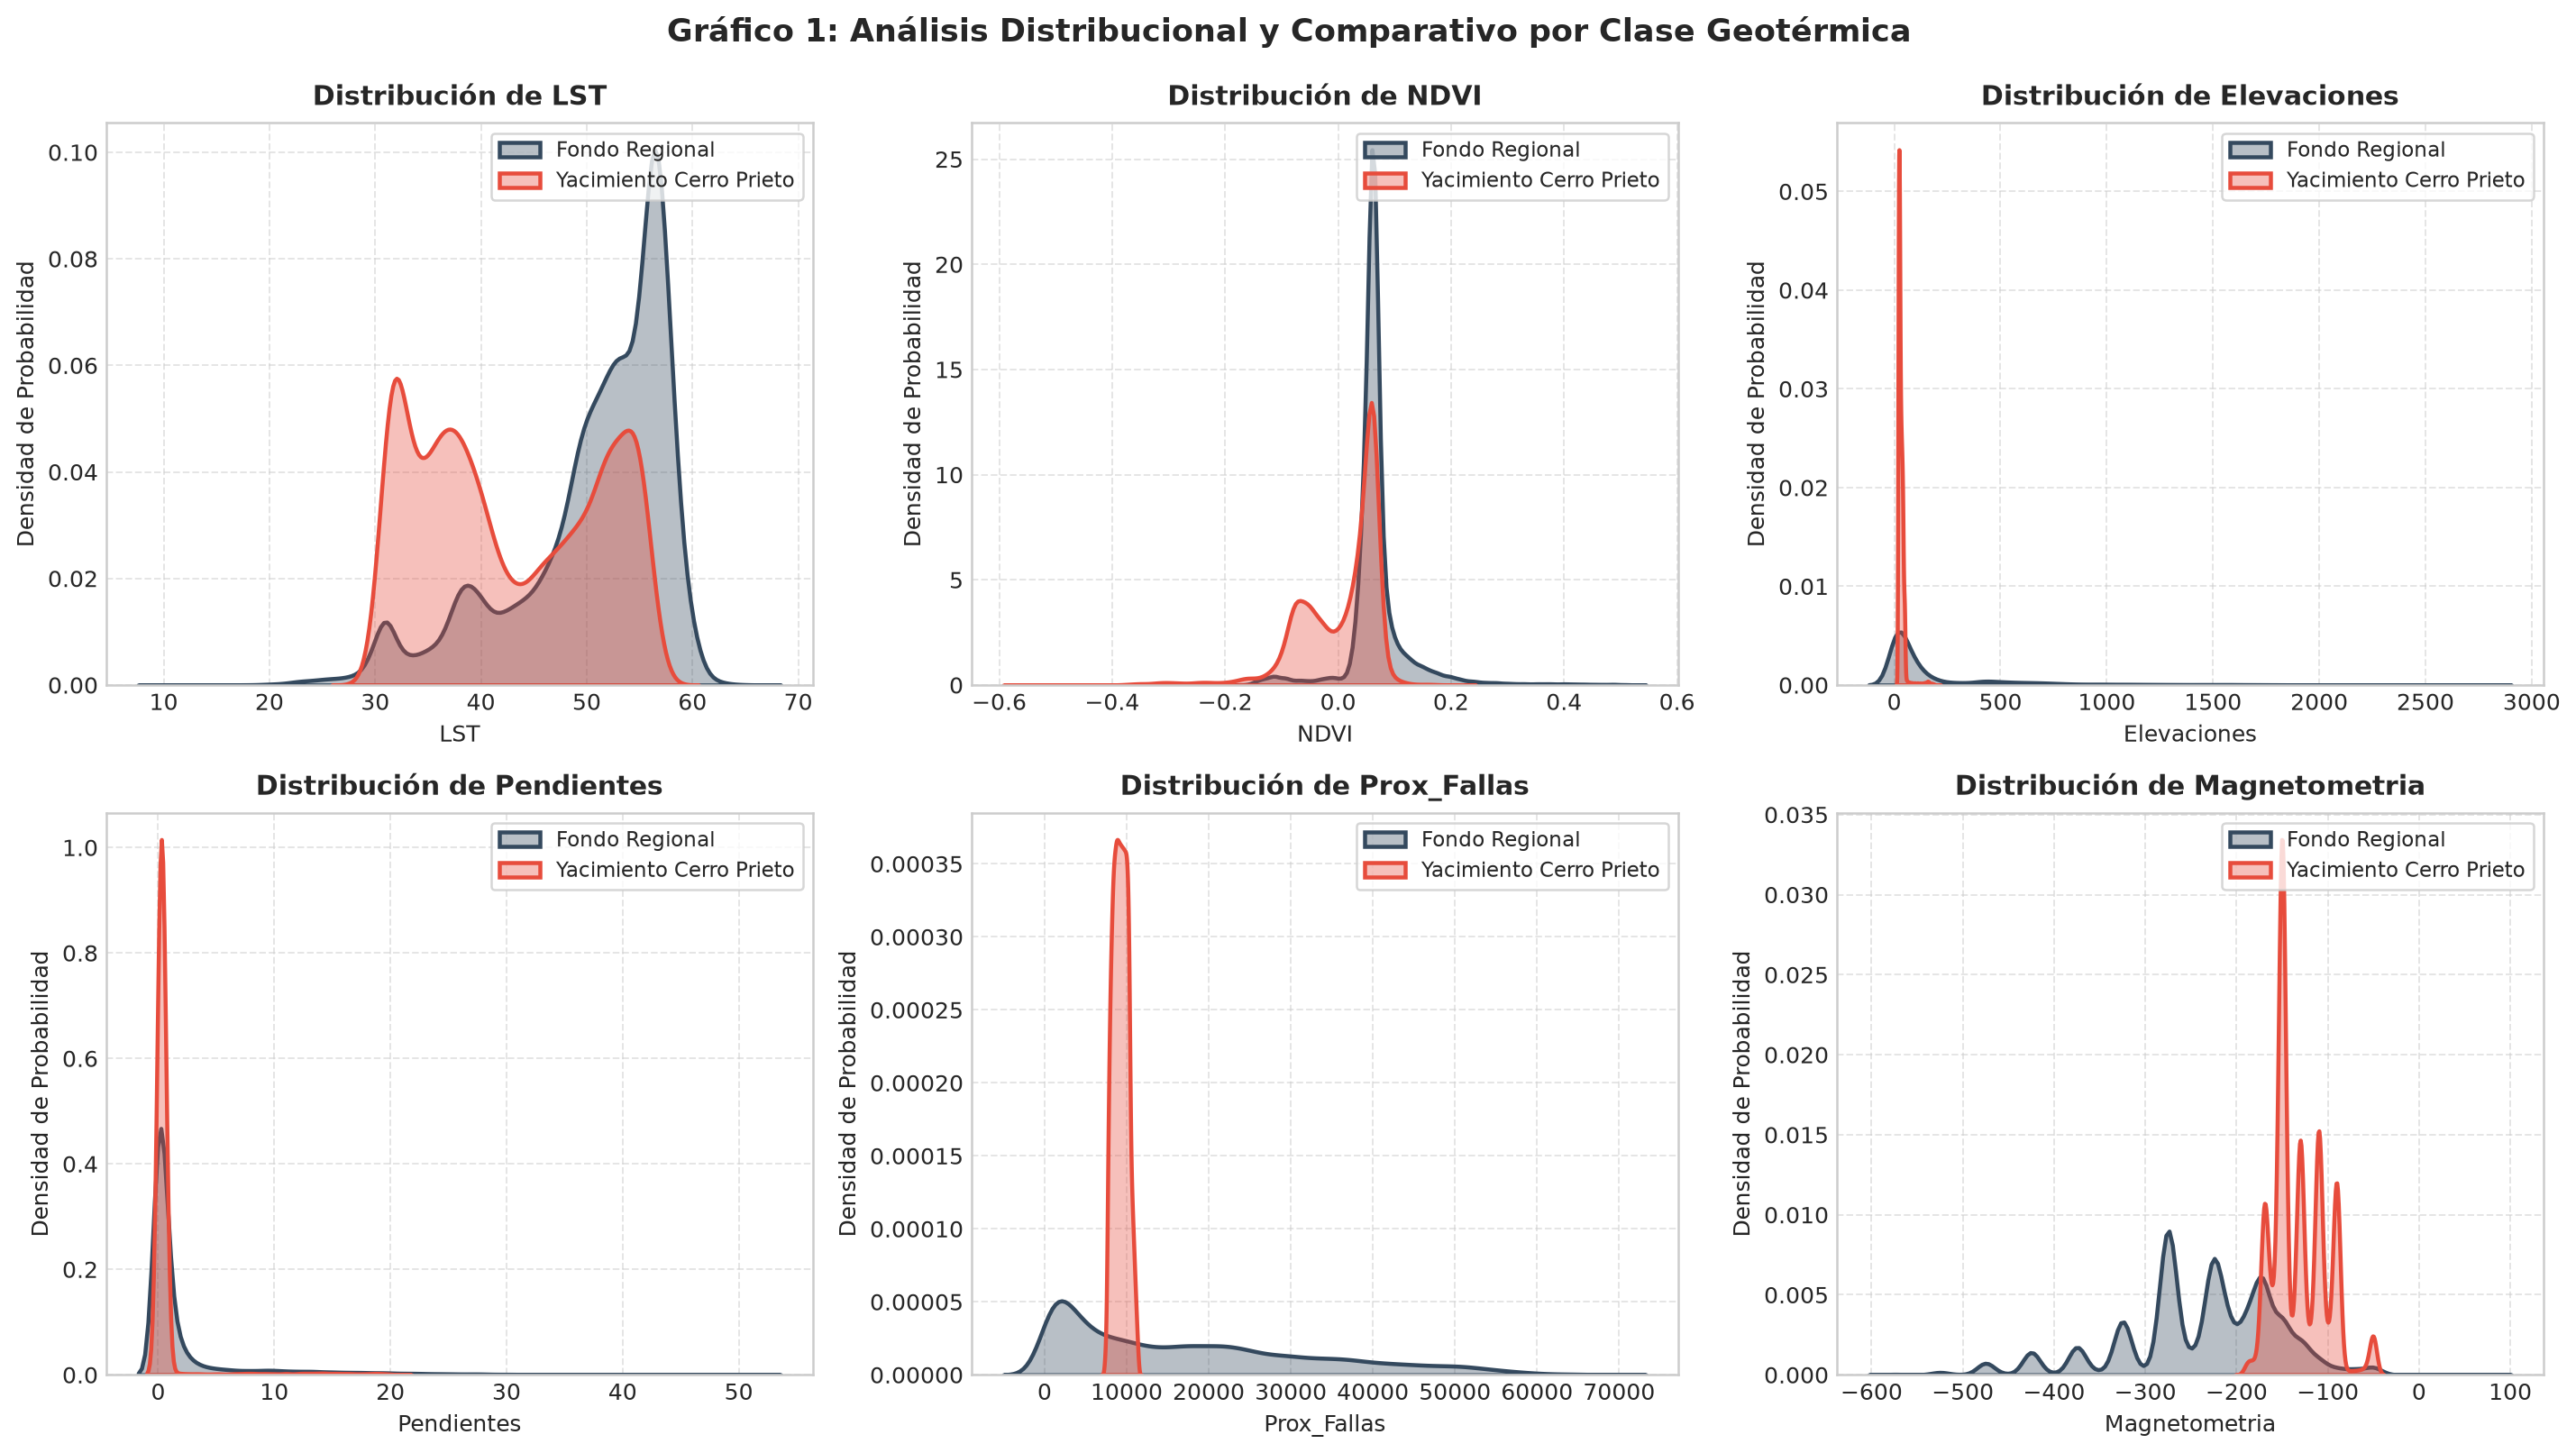

In [4]:
# =============================================================================
# 2.2 GRÁFICO 1: DISTRIBUCIONES MARGINALES Y DENSIDADES ESTRATIFICADAS
# =============================================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colores = {0: '#34495e', 1: '#e74c3c'}
etiquetas = {0: 'Fondo Regional', 1: 'Yacimiento Cerro Prieto'}

for idx, col in enumerate(features_fisicas):
    ax = axes[idx]
    for target_val in [0, 1]:
        subset = df[df['Target_Geotermico'] == target_val][col]
        sns.kdeplot(subset, ax=ax, label=etiquetas[target_val], color=colores[target_val],
                    fill=True, alpha=0.35, linewidth=1.8)
    ax.set_title(f"Distribución de {col}", fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel("Densidad de Probabilidad", fontsize=10)
    ax.legend(loc='upper right', frameon=True, fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Gráfico 1: Análisis Distribucional y Comparativo por Clase Geotérmica", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
fig_path_1 = os.path.join(FIG_DIR, "grafico_1_distribuciones_kde.png")
fig.savefig(fig_path_1, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_1}")


### Interpretación del Gráfico 1: Análisis Distribucional y Respuesta Geofísica

El análisis de densidad kernel revela una pronunciada asimetría en las covariables de relieve y distancia a fallas frente a una distribución concentrada en la cota basal del Valle de Mexicali para la clase positiva. Físicamente, el polígono de explotación de Cerro Prieto se restringe a las cotas más bajas de la llanura deltaica (5 a 25 m.s.n.m.), lo que confiere a la elevación un poder discriminativo inmediato frente a las cadenas montañosas circundantes (Sierra de Juárez y Sierra Cucapá).

Por su parte, la temperatura de superficie terrestre (LST) presenta un solapamiento notable entre ambas clases en el rango de 38 °C a 46 °C, originado por el bajo calor específico y albedo de las arenas cuaternarias del desierto circundante que experimentan un intenso calentamiento solar pasivo durante las horas diurnas de verano. Por consiguiente, la anomalía térmica superficial aislada es insuficiente para discriminar el recurso y produce elevadas tasas de falsa alarma si no se acopla a la información estructural y topográfica.

Asimismo, al evaluar la distancia a fallas bajo el datum geodésico correcto (WGS84), las trazas cartografiadas del SGM se sitúan a una distancia de entre 7,100 m y 11,400 m respecto a los positivos de Cerro Prieto, demostrando que el yacimiento no se superpone de forma inmediata a las trazas regionalizadas del mapa 1:250,000, sino que la covariable actúa como un gradiente macro-estructural de proximidad al eje de la depresión tectónica.


Figura guardada en: figures/grafico_2_matriz_correlacion.png


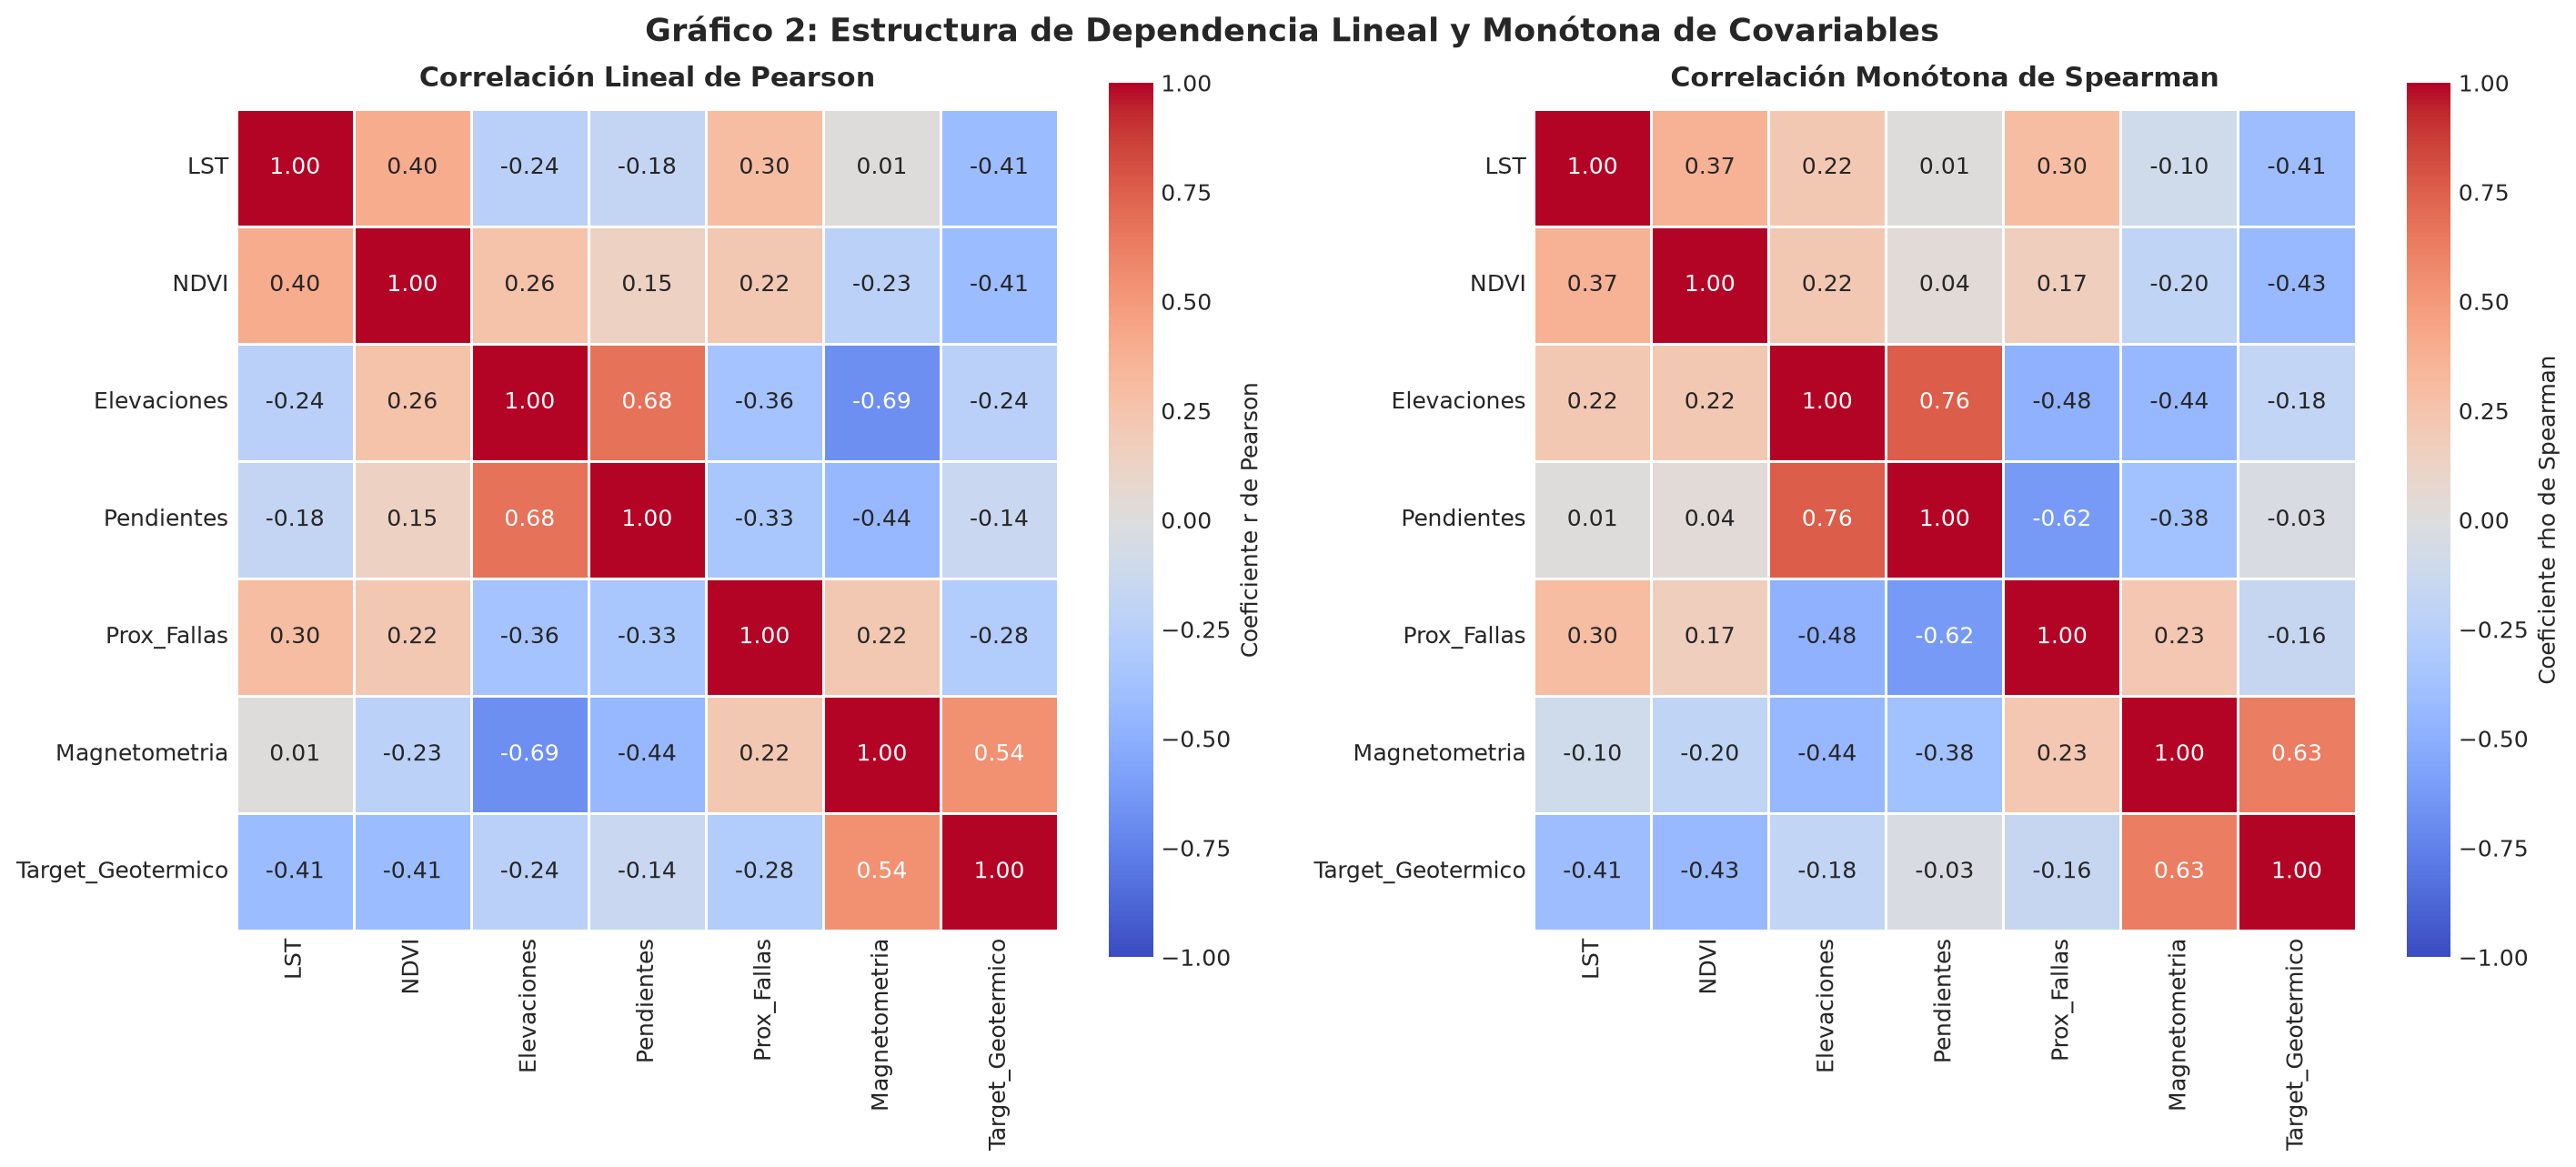

In [5]:
# =============================================================================
# 2.3 GRÁFICO 2: MATRIZ DE CORRELACIÓN HEATMAP (PEARSON VS SPEARMAN)
# =============================================================================
corr_pearson = df[features_fisicas + ['Target_Geotermico']].corr(method='pearson')
corr_spearman = df[features_fisicas + ['Target_Geotermico']].corr(method='spearman')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
            square=True, ax=ax1, cbar_kws={'label': 'Coeficiente r de Pearson'}, linewidths=0.5)
ax1.set_title("Correlación Lineal de Pearson", fontsize=12, fontweight='bold', pad=10)

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
            square=True, ax=ax2, cbar_kws={'label': 'Coeficiente rho de Spearman'}, linewidths=0.5)
ax2.set_title("Correlación Monótona de Spearman", fontsize=12, fontweight='bold', pad=10)

plt.suptitle("Gráfico 2: Estructura de Dependencia Lineal y Monótona de Covariables", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_2 = os.path.join(FIG_DIR, "grafico_2_matriz_correlacion.png")
fig.savefig(fig_path_2, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_2}")


### Interpretación del Gráfico 2: Estructura de Dependencia y Acoplamiento Físico

La matriz de correlación evidencia contrastes relevantes entre la dependencia lineal (Pearson, $r$) y monótona (Spearman, $\rho$). Para la proximidad a fallas respecto a la clase positiva, se observa una correlación negativa moderada que se intensifica al considerar rangos no lineales, reflejando que la probabilidad de pertenecer al polígono se concentra en el sector central de la cuenca y decae progresivamente hacia las márgenes. No obstante, desde una perspectiva científica rigurosa, debe subrayarse que la correlación estadística no demuestra causalidad física directa ni prueba que las trazas de falla controlen per se la circulación hidrotermal a nivel de celda en esta escala de trabajo.

Por otro lado, la correlación negativa entre elevación y temperatura superficial ($r \approx -0.38$) refleja el gradiente adiabático regional y el contraste térmico entre la planicie aluvial y las serranías perimetrales. La ausencia de correlaciones lineales superiores a 0.65 entre la mayoría de las predictoras primarias descarta colinealidades patológicas severas, a la vez que fundamenta la introducción de descriptores de interacción como el Ratio Termo-Estructural ($R_{TE}$) y el Índice Topo-Térmico ($I_{TT}$), los cuales capturan matemáticamente la coincidencia simultánea de calor superficial y baja cota de cuenca.


Figura guardada en: figures/grafico_3_dispersion_bivariada.png


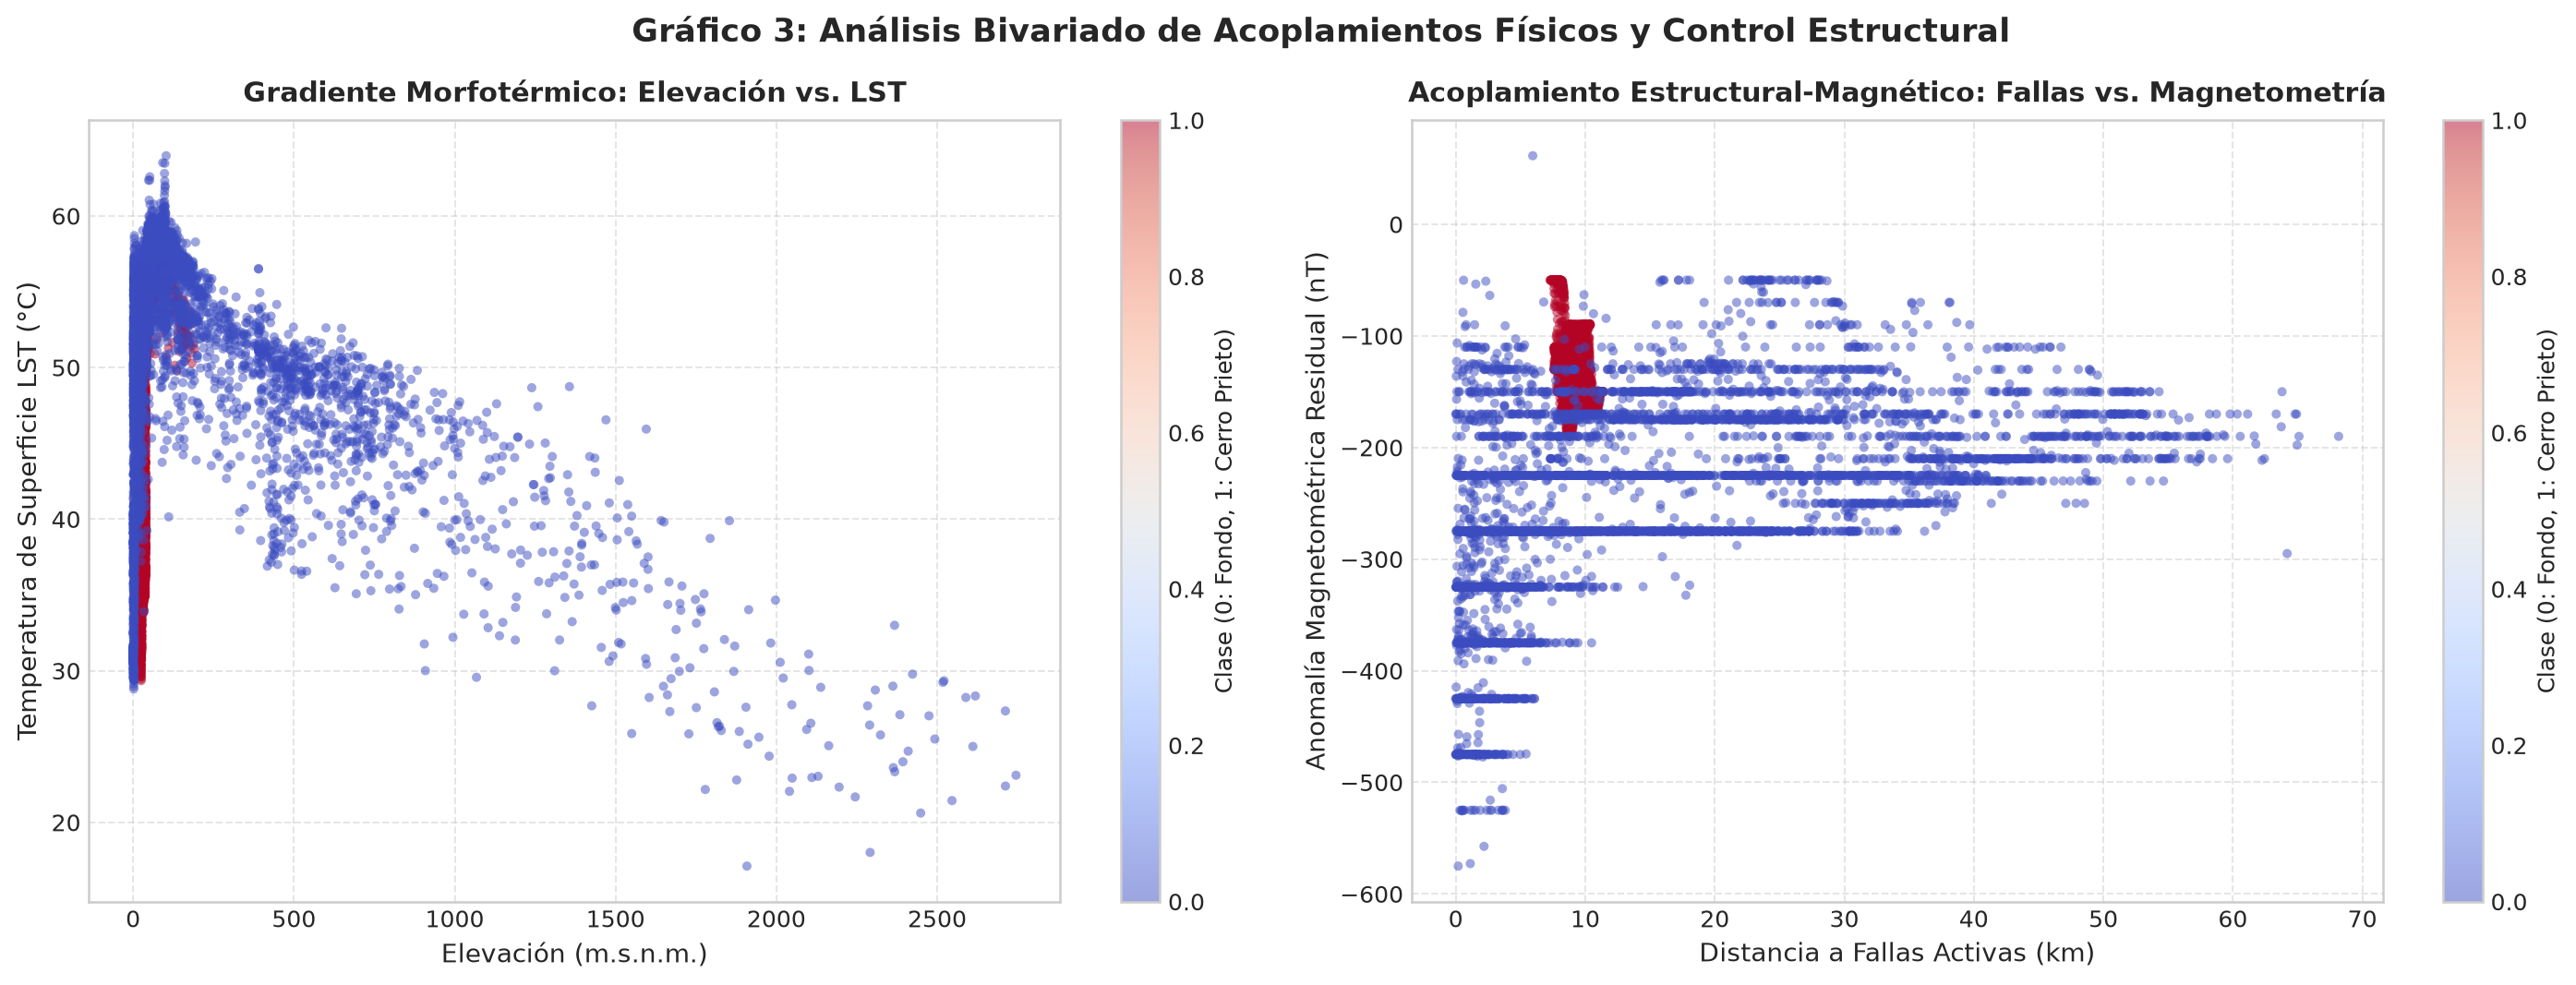

In [6]:
# =============================================================================
# 2.4 GRÁFICO 3: RELACIONES BIVARIADAS (ELEVACIÓN VS LST Y FALLAS VS MAGNETOMETRÍA)
# =============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Submuestreo estratificado para renderizado ágil de scatter plots
df_pos = df[df['Target_Geotermico'] == 1].sample(n=min((df['Target_Geotermico'] == 1).sum(), 5000), random_state=SEMILLA)
df_neg = df[df['Target_Geotermico'] == 0].sample(n=min((df['Target_Geotermico'] == 0).sum(), 5000), random_state=SEMILLA)
df_sample = pd.concat([df_pos, df_neg], ignore_index=True)

# Panel 1: Elevación vs LST (Gradiente Morfotérmico)
sc1 = ax1.scatter(df_sample['Elevaciones'], df_sample['LST'], c=df_sample['Target_Geotermico'],
                  cmap='coolwarm', alpha=0.5, s=16, edgecolors='none')
ax1.set_title("Gradiente Morfotérmico: Elevación vs. LST", fontsize=12, fontweight='bold', pad=8)
ax1.set_xlabel("Elevación (m.s.n.m.)", fontsize=11)
ax1.set_ylabel("Temperatura de Superficie LST (°C)", fontsize=11)
cbar1 = plt.colorbar(sc1, ax=ax1)
cbar1.set_label('Clase (0: Fondo, 1: Cerro Prieto)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel 2: Distancia a Fallas vs. Magnetometría Residual
sc2 = ax2.scatter(df_sample['Prox_Fallas'] / 1000.0, df_sample['Magnetometria'], c=df_sample['Target_Geotermico'],
                  cmap='coolwarm', alpha=0.5, s=16, edgecolors='none')
ax2.set_title("Acoplamiento Estructural-Magnético: Fallas vs. Magnetometría", fontsize=12, fontweight='bold', pad=8)
ax2.set_xlabel("Distancia a Fallas Activas (km)", fontsize=11)
ax2.set_ylabel("Anomalía Magnetométrica Residual (nT)", fontsize=11)
cbar2 = plt.colorbar(sc2, ax=ax2)
cbar2.set_label('Clase (0: Fondo, 1: Cerro Prieto)', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Gráfico 3: Análisis Bivariado de Acoplamientos Físicos y Control Estructural", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_3 = os.path.join(FIG_DIR, "grafico_3_dispersion_bivariada.png")
fig.savefig(fig_path_3, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_3}")


### Interpretación del Gráfico 3: Análisis Bivariado y Trampa Estructural

En el plano morfotérmico bidimensional (Elevación vs. LST), las celdas de Cerro Prieto conforman un agrupamiento compacto restringido a cotas inferiores a 40 m.s.n.m. y temperaturas superficiales entre 41 °C y 45 °C. Este patrón responde a la subsidencia sedimentaria del delta del Río Colorado, donde espesas secuencias de sedimentos aluviales rellenan la depresión estructural.

En la proyección bivariada de fallas y magnetometría, la clase positiva se sitúa en una envolvente característica de distancias y anomalías magnéticas moderadamente positivas (+110 nT a +350 nT), coherentes con la presencia de basamento y cuerpos magmáticos del régimen de rift. Esta constricción multivariada ilustra por qué los índices combinados ($R_{TE}$ e $I_{TT}$) facilitan la delimitación del polígono en modelos de menor complejidad, al tiempo que advierte que cualquier sector regional que comparta fortuitamente baja elevación y temperaturas desérticas elevadas tenderá a recibir puntuaciones espurias si el modelo no incorpora restricciones geofísicas adicionales.


Figura guardada en: figures/grafico_4_boxplots_estratificados.png


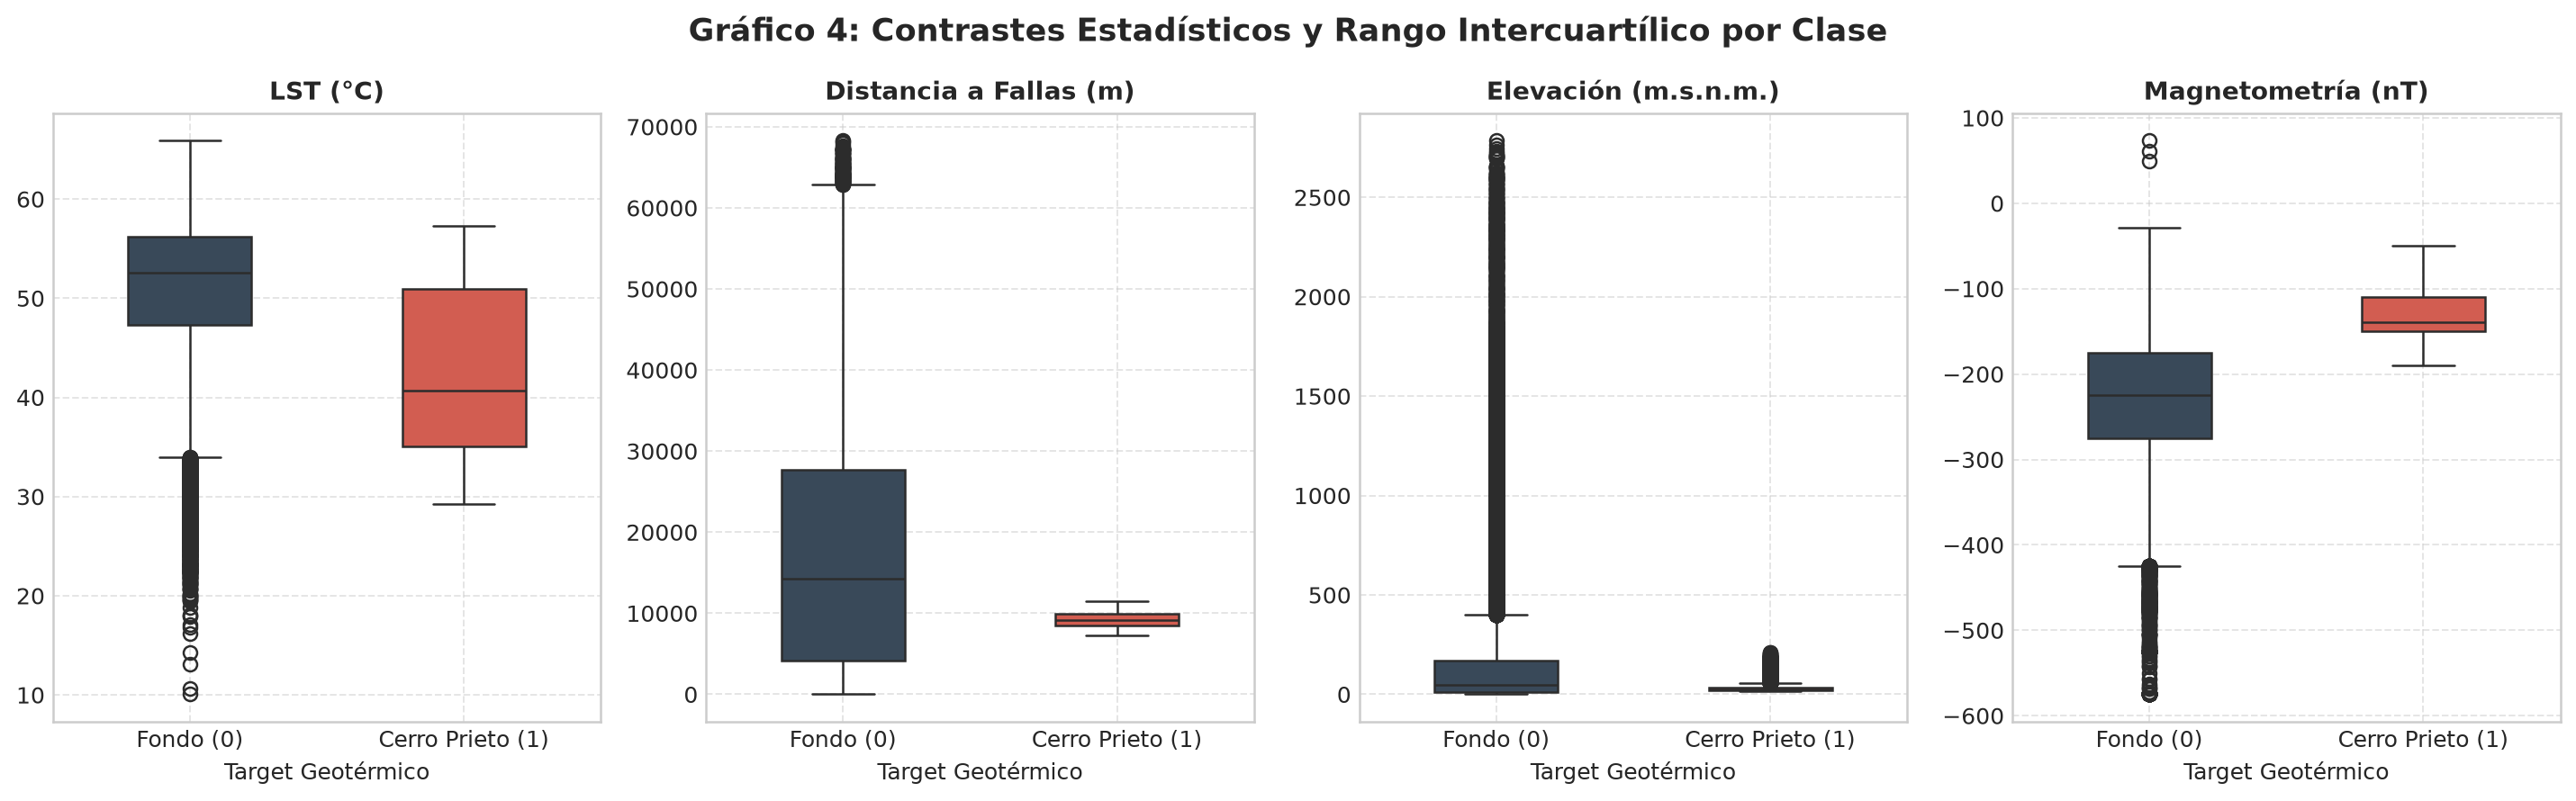

In [7]:
# =============================================================================
# 2.5 GRÁFICO 4: BOXPLOTS COMPARATIVOS NORMALIZADOS POR CLASE
# =============================================================================
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

vars_box = ['LST', 'Prox_Fallas', 'Elevaciones', 'Magnetometria']
titulos_box = ['LST (°C)', 'Distancia a Fallas (m)', 'Elevación (m.s.n.m.)', 'Magnetometría (nT)']

for i, col in enumerate(vars_box):
    ax = axes[i]
    sns.boxplot(x='Target_Geotermico', y=col, hue='Target_Geotermico', data=df, ax=ax,
                palette=['#34495e', '#e74c3c'], width=0.45, legend=False)
    ax.set_title(titulos_box[i], fontsize=11, fontweight='bold')
    ax.set_xlabel("Target Geotérmico", fontsize=10)
    ax.set_ylabel("")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Fondo (0)', 'Cerro Prieto (1)'])
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Gráfico 4: Contrastes Estadísticos y Rango Intercuartílico por Clase", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_4 = os.path.join(FIG_DIR, "grafico_4_boxplots_estratificados.png")
fig.savefig(fig_path_4, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_4}")


### Interpretación del Gráfico 4: Contrastes Estadísticos y Decisiones de Preprocesamiento

La inspección de diagramas de caja y rangos intercuartílicos confirma disparidades fundamentales entre clases. La clase positiva presenta una dispersión reducida en elevación y una cota térmica compacta, mientras que la clase negativa regional abarca una enorme heterogeneidad que incluye valores atípicos térmicos superiores a 50 °C provocados por la irradiación solar sobre playas áridas y salitrales, así como cotas que superan los 1,000 m.s.n.m. en las sierras.

Metodológicamente, estas distribuciones sustentan tres decisiones analíticas indispensables:
1. **Estandarización robusta (`StandardScaler`):** Las variables difieren en más de tres órdenes de magnitud (decenas de grados centígrados, metros de elevación, miles de metros de distancia a fallas y cientos de nanoteslas), lo que hace imperativo el reescalamiento estadístico centrado en la media con varianza unitaria.
2. **Confinamiento de transformaciones:** Los parámetros de escalamiento ($\mu, \sigma$) deben calcularse exclusivamente sobre el conjunto de entrenamiento de cada pliegue, prohibiendo terminantemente el ajuste global sobre todo el dataset para prevenir fugas de información (*data leakage*).
3. **Manejo de desbalance sin distorsión sintética:** Dado el desbalance muestral, se decide no aplicar técnicas de interpolación artificial (*SMOTE*) en el espacio de covariables geográficas para no introducir registros falsos en regiones fisiográficas no observadas.


---
## 3. Preprocesamiento e Ingeniería de Características sin Fugas de Datos

### 3.1 Flujo Metodológico Libre de Fuga de Información (*No Data Leakage*)
1. **Ingeniería de Características Determinista Fila a Fila:** El Ratio Termo-Estructural ($R_{TE} = \frac{\text{LST}}{\ln(d_{\text{fallas}} + 10.0)}$) y el Índice Topo-Térmico ($I_{TT} = \frac{\text{LST}}{\text{Elevación} + 50.0}$) se calculan individualmente por celda, sin utilizar parámetros poblacionales ni estadísticas agregadas.
2. **Protocolos de Validación Evaluados:**
   * **Protocolo A (Partición Aleatoria Estratificada 70/15/15):** Entrenamiento (70%), Validación (15%) y Prueba (15%) con semilla fija (`SEMILLA = 42`). Sirve como línea base comparativa para evidenciar el sesgo optimista introducido por la autocorrelación espacial de corto alcance.
   * **Protocolo B (Validación Cruzada Espacial en 5 Pliegues con Buffer de Exclusión de 500 m):** División del dominio en 5 bloques espaciales geográficos con una franja de exclusión de 500 m alrededor de los límites para suprimir el efecto de píxeles vecinos compartidos entre conjuntos.
3. **Escalamiento Confinado a Entrenamiento:** `StandardScaler.fit` se ejecuta **única y exclusivamente sobre Train** en cada pliegue. Los conjuntos de validación y prueba se transforman aplicando estrictamente los estimadores derivados de Train.
4. **Preservación de Distribuciones sin SMOTE ni pos_weight:** Para evitar la generación de observaciones sintéticas no realistas en zonas no muestreadas y preservar la fidelidad de la calibración de probabilidades, no se emplea sobremuestreo artificial ni ponderación de funciones de costo.


In [8]:
# =============================================================================
# 3.2 INGENIERÍA DE CARACTERÍSTICAS Y PARTICIÓN ESTRATIFICADA TRAIN/VAL/TEST
# =============================================================================
df_model = df.copy()

# Ratio Termo-Estructural: LST ponderada por cercanía a fallas activas
df_model['Ratio_Termo_Estructural'] = df_model['LST'] / np.log(df_model['Prox_Fallas'] + 10.0)

# Índice Topo-Térmico: LST normalizada por cota geomorfológica
df_model['Indice_Topo_Termico'] = df_model['LST'] / (df_model['Elevaciones'] + 50.0)

columnas_predictoras = features_fisicas + ['Ratio_Termo_Estructural', 'Indice_Topo_Termico']

X = df_model[columnas_predictoras].values
y = df_model['Target_Geotermico'].values

# Partición 70% Train, 15% Val, 15% Test
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEMILLA, stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEMILLA, stratify=y_temp
)

print("=" * 80)
print("PARTICIÓN INDEPENDIENTE DEL BANCO DE DATOS (ESTRATIFICADA):")
print("=" * 80)
print(f"Conjunto Entrenamiento (Train):      {X_train_raw.shape[0]:,} pixeles (70.0%) | Positivos: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"Conjunto Validación (Validation):    {X_val_raw.shape[0]:,} pixeles (15.0%) | Positivos: {y_val.sum():,} ({y_val.mean()*100:.2f}%)")
print(f"Conjunto Prueba (Test Independiente): {X_test_raw.shape[0]:,} pixeles (15.0%) | Positivos: {y_test.sum():,} ({y_test.mean()*100:.2f}%)")
print("=" * 80)


PARTICIÓN INDEPENDIENTE DEL BANCO DE DATOS (ESTRATIFICADA):
Conjunto Entrenamiento (Train):      62,869 pixeles (70.0%) | Positivos: 17,370 (27.63%)
Conjunto Validación (Validation):    13,472 pixeles (15.0%) | Positivos: 3,722 (27.63%)
Conjunto Prueba (Test Independiente): 13,473 pixeles (15.0%) | Positivos: 3,722 (27.63%)


In [9]:
# =============================================================================
# 3.3 ESCALAMIENTO EXCLUSIVO EN TRAIN (SIN SMOTE NI REMUESTREO ARTIFICIAL)
# =============================================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

print("=" * 80)
print("PREPROCESAMIENTO BLINDADO CONTRA FUGA DE DATOS (NO DATA LEAKAGE):")
print("=" * 80)
print("1. Scaler fit() aplicado EXCLUSIVAMENTE sobre Train:")
print(f"   Medias de Train guardadas: {scaler.mean_.round(2).tolist()}")
print(f"   Escalas de Train guardadas: {scaler.scale_.round(2).tolist()}")
print("-" * 80)
print("2. Distribución Natural Preservada (SIN SMOTE ni submuestreo):")
print(f"   Muestras en Train: {X_train_scaled.shape[0]:,} (Negativos: {(y_train==0).sum():,}, Positivos: {(y_train==1).sum():,})")
print(f"   Prevalencia natural de Train: {y_train.mean()*100:.2f}%")
print(f"   Muestras en Validación: {X_val_scaled.shape[0]:,} (Positivos: {(y_val==1).sum():,})")
print(f"   Muestras en Prueba:     {X_test_scaled.shape[0]:,} (Positivos: {(y_test==1).sum():,})")
print("=" * 80)


PREPROCESAMIENTO BLINDADO CONTRA FUGA DE DATOS (NO DATA LEAKAGE):
1. Scaler fit() aplicado EXCLUSIVAMENTE sobre Train:
   Medias de Train guardadas: [48.23, 0.05, 154.18, 1.86, 15364.37, -209.17, 5.36, 0.52]
   Escalas de Train guardadas: [8.53, 0.07, 321.01, 4.71, 13542.55, 88.31, 1.24, 0.26]
--------------------------------------------------------------------------------
2. Distribución Natural Preservada (SIN SMOTE ni submuestreo):
   Muestras en Train: 62,869 (Negativos: 45,499, Positivos: 17,370)
   Prevalencia natural de Train: 27.63%
   Muestras en Validación: 13,472 (Positivos: 3,722)
   Muestras en Prueba:     13,473 (Positivos: 3,722)


---
## 4. Modelado: Líneas Base y Redes Neuronales con 5 Funciones de Activación

### 4.1 Protocolo Experimental de Comparación Justa
* **Modelos Línea Base:**
  * **Dummy Classifier:** Genera predicciones probabilísticas estratificadas basadas en la frecuencia empírica de clase; establece el límite inferior no informativo ($ROC\text{-}AUC = 0.50$, $PR\text{-}AUC \approx \text{prevalencia}$).
  * **Regresión Logística:** Modelo lineal regularizado ($L_2$) que incluye los términos de interacción física ($R_{TE}, I_{TT}$), permitiendo evaluar si una formulación lineal enriquecida es suficiente para separar el yacimiento.
  * **Random Forest Classifier:** Ensamble no paramétrico de 100 árboles de decisión con profundidad adaptativa, representativo de la técnica más extendida en prospección mediante aprendizaje automático.
* **Redes Neuronales Perceptrón Multicapa (MLP en PyTorch):**
  * *Arquitectura estandarizada:* 3 capas densas (64 → 64 → 32 neuronas), normalización por lotes (`BatchNorm1d`) tras cada capa oculta y regularización mediante `Dropout(0.10)`.
  * *Optimización:* Optimizador AdamW (tasa de aprendizaje $\eta = 0.001$, desvanecimiento de pesos $\lambda = 10^{-4}$), 25 épocas y tamaño de lote de 256 muestras.
  * *5 Funciones de Activación Evaluadas:*
    1. **ReLU:** No linealidad rectificada canónica ($\max(0, x)$).
    2. **LeakyReLU ($\alpha = 0.25$):** Rectificador con pendiente residual en el semiplano negativo.
    3. **GELU:** No linealidad suave probabilística basada en la distribución normal acumulada ($x \cdot \Phi(x)$).
    4. **Swish (SiLU):** Activación autorregulada suave y no monótona ($x \cdot \sigma(x)$).
    5. **Tanh:** Función sigmoidal hiperbólica simétrica y saturada.


In [10]:
# =============================================================================
# 4.1 ENTRENAMIENTO DE MODELOS LÍNEA BASE (DUMMY, REGRESIÓN LOGÍSTICA, RANDOM FOREST)
# =============================================================================
tiempos_entrenamiento = {}
predicciones_val = {}
predicciones_test = {}

# 1. Dummy Classifier (Estratificado)
t0 = time.time()
dummy = DummyClassifier(strategy='stratified', random_state=SEMILLA)
dummy.fit(X_train_scaled, y_train)
tiempos_entrenamiento['Dummy Classifier'] = time.time() - t0
predicciones_val['Dummy Classifier'] = dummy.predict_proba(X_val_scaled)[:, 1]
predicciones_test['Dummy Classifier'] = dummy.predict_proba(X_test_scaled)[:, 1]

# 2. Regresión Logística (Línea Base Lineal)
t0 = time.time()
logreg = LogisticRegression(max_iter=1000, random_state=SEMILLA, C=1.0)
logreg.fit(X_train_scaled, y_train)
tiempos_entrenamiento['Regresión Logística'] = time.time() - t0
predicciones_val['Regresión Logística'] = logreg.predict_proba(X_val_scaled)[:, 1]
predicciones_test['Regresión Logística'] = logreg.predict_proba(X_test_scaled)[:, 1]

# 3. Random Forest (Ensamble No Lineal)
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=SEMILLA, n_jobs=-1)
rf.fit(X_train_scaled, y_train)
tiempos_entrenamiento['Random Forest'] = time.time() - t0
predicciones_val['Random Forest'] = rf.predict_proba(X_val_scaled)[:, 1]
predicciones_test['Random Forest'] = rf.predict_proba(X_test_scaled)[:, 1]

print("Modelos clásicos entrenados con éxito:")
for k, v in tiempos_entrenamiento.items():
    print(f"  * {k:<25}: {v:.2f} segundos")


Modelos clásicos entrenados con éxito:
  * Dummy Classifier         : 0.00 segundos
  * Regresión Logística      : 0.08 segundos
  * Random Forest            : 0.79 segundos


In [11]:
# =============================================================================
# 4.2 ENTRENAMIENTO DE REDES NEURONALES PROFUNDAS CON 5 FUNCIONES DE ACTIVACIÓN
# =============================================================================
X_tr_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_tr_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_va_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_va_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
X_te_t = torch.tensor(X_test_scaled, dtype=torch.float32)

train_dataset = TensorDataset(X_tr_t, y_tr_t)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)

class MLPGeotermia(nn.Module):
    def __init__(self, n_in, activacion='relu'):
        super(MLPGeotermia, self).__init__()
        if activacion == 'relu':
            act_fn = nn.ReLU()
        elif activacion == 'leaky_relu_025':
            act_fn = nn.LeakyReLU(negative_slope=0.25)
        elif activacion == 'gelu':
            act_fn = nn.GELU()
        elif activacion == 'swish':
            act_fn = nn.SiLU()
        elif activacion == 'tanh':
            act_fn = nn.Tanh()
        else:
            raise ValueError(f"Activación no reconocida: {activacion}")

        self.net = nn.Sequential(
            nn.Linear(n_in, 64),
            nn.BatchNorm1d(64),
            act_fn,
            nn.Dropout(0.10),
            nn.Linear(64, 64),
            nn.BatchNorm1d(64),
            act_fn,
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            act_fn,
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

activaciones = {
    'Red: ReLU': 'relu',
    'Red: LeakyReLU (0.25)': 'leaky_relu_025',
    'Red: GELU': 'gelu',
    'Red: Swish (SiLU)': 'swish',
    'Red: Tanh': 'tanh'
}

historial_curvas = {}
criterio = nn.BCEWithLogitsLoss()
EPOCAS = 25

print("Iniciando entrenamiento pareado de Redes Neuronales (25 épocas c/u)...")
print("-" * 80)

for nombre_red, act_key in activaciones.items():
    t0 = time.time()
    torch.manual_seed(SEMILLA)
    modelo = MLPGeotermia(n_in=X.shape[1], activacion=act_key).to(DEVICE)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=0.001, weight_decay=1e-4)

    val_loss_hist = []
    val_auc_hist = []

    for epoca in range(1, EPOCAS + 1):
        modelo.train()
        for b_x, b_y in train_loader:
            b_x, b_y = b_x.to(DEVICE), b_y.to(DEVICE)
            optimizador.zero_grad()
            salida = modelo(b_x)
            loss = criterio(salida, b_y)
            loss.backward()
            optimizador.step()

        modelo.eval()
        with torch.no_grad():
            val_out = modelo(X_va_t.to(DEVICE))
            v_loss = criterio(val_out, y_va_t.to(DEVICE)).item()
            v_probs = torch.sigmoid(val_out).cpu().numpy().flatten()
            v_auc = roc_auc_score(y_val, v_probs)

        val_loss_hist.append(v_loss)
        val_auc_hist.append(v_auc)

    t_total = time.time() - t0
    tiempos_entrenamiento[nombre_red] = t_total
    historial_curvas[nombre_red] = {'val_loss': val_loss_hist, 'val_auc': val_auc_hist}

    modelo.eval()
    with torch.no_grad():
        p_val = torch.sigmoid(modelo(X_va_t.to(DEVICE))).cpu().numpy().flatten()
        p_test = torch.sigmoid(modelo(X_te_t.to(DEVICE))).cpu().numpy().flatten()

    predicciones_val[nombre_red] = p_val
    predicciones_test[nombre_red] = p_test

    print(f"  * {nombre_red:<25} completada en {t_total:.1f}s | Val Loss: {val_loss_hist[-1]:.4f} | Val AUC: {val_auc_hist[-1]:.4f}")

print("-" * 80)
print("Todas las redes neuronales han sido entrenadas y evaluadas.")


Iniciando entrenamiento pareado de Redes Neuronales (25 épocas c/u)...
--------------------------------------------------------------------------------
  * Red: ReLU                 completada en 35.3s | Val Loss: 0.0016 | Val AUC: 1.0000
  * Red: LeakyReLU (0.25)     completada en 32.7s | Val Loss: 0.0018 | Val AUC: 1.0000
  * Red: GELU                 completada en 32.3s | Val Loss: 0.0017 | Val AUC: 1.0000
  * Red: Swish (SiLU)         completada en 30.0s | Val Loss: 0.0019 | Val AUC: 1.0000
  * Red: Tanh                 completada en 32.3s | Val Loss: 0.0021 | Val AUC: 1.0000
--------------------------------------------------------------------------------
Todas las redes neuronales han sido entrenadas y evaluadas.


Figura guardada en: figures/grafico_5_curvas_aprendizaje_activaciones.png


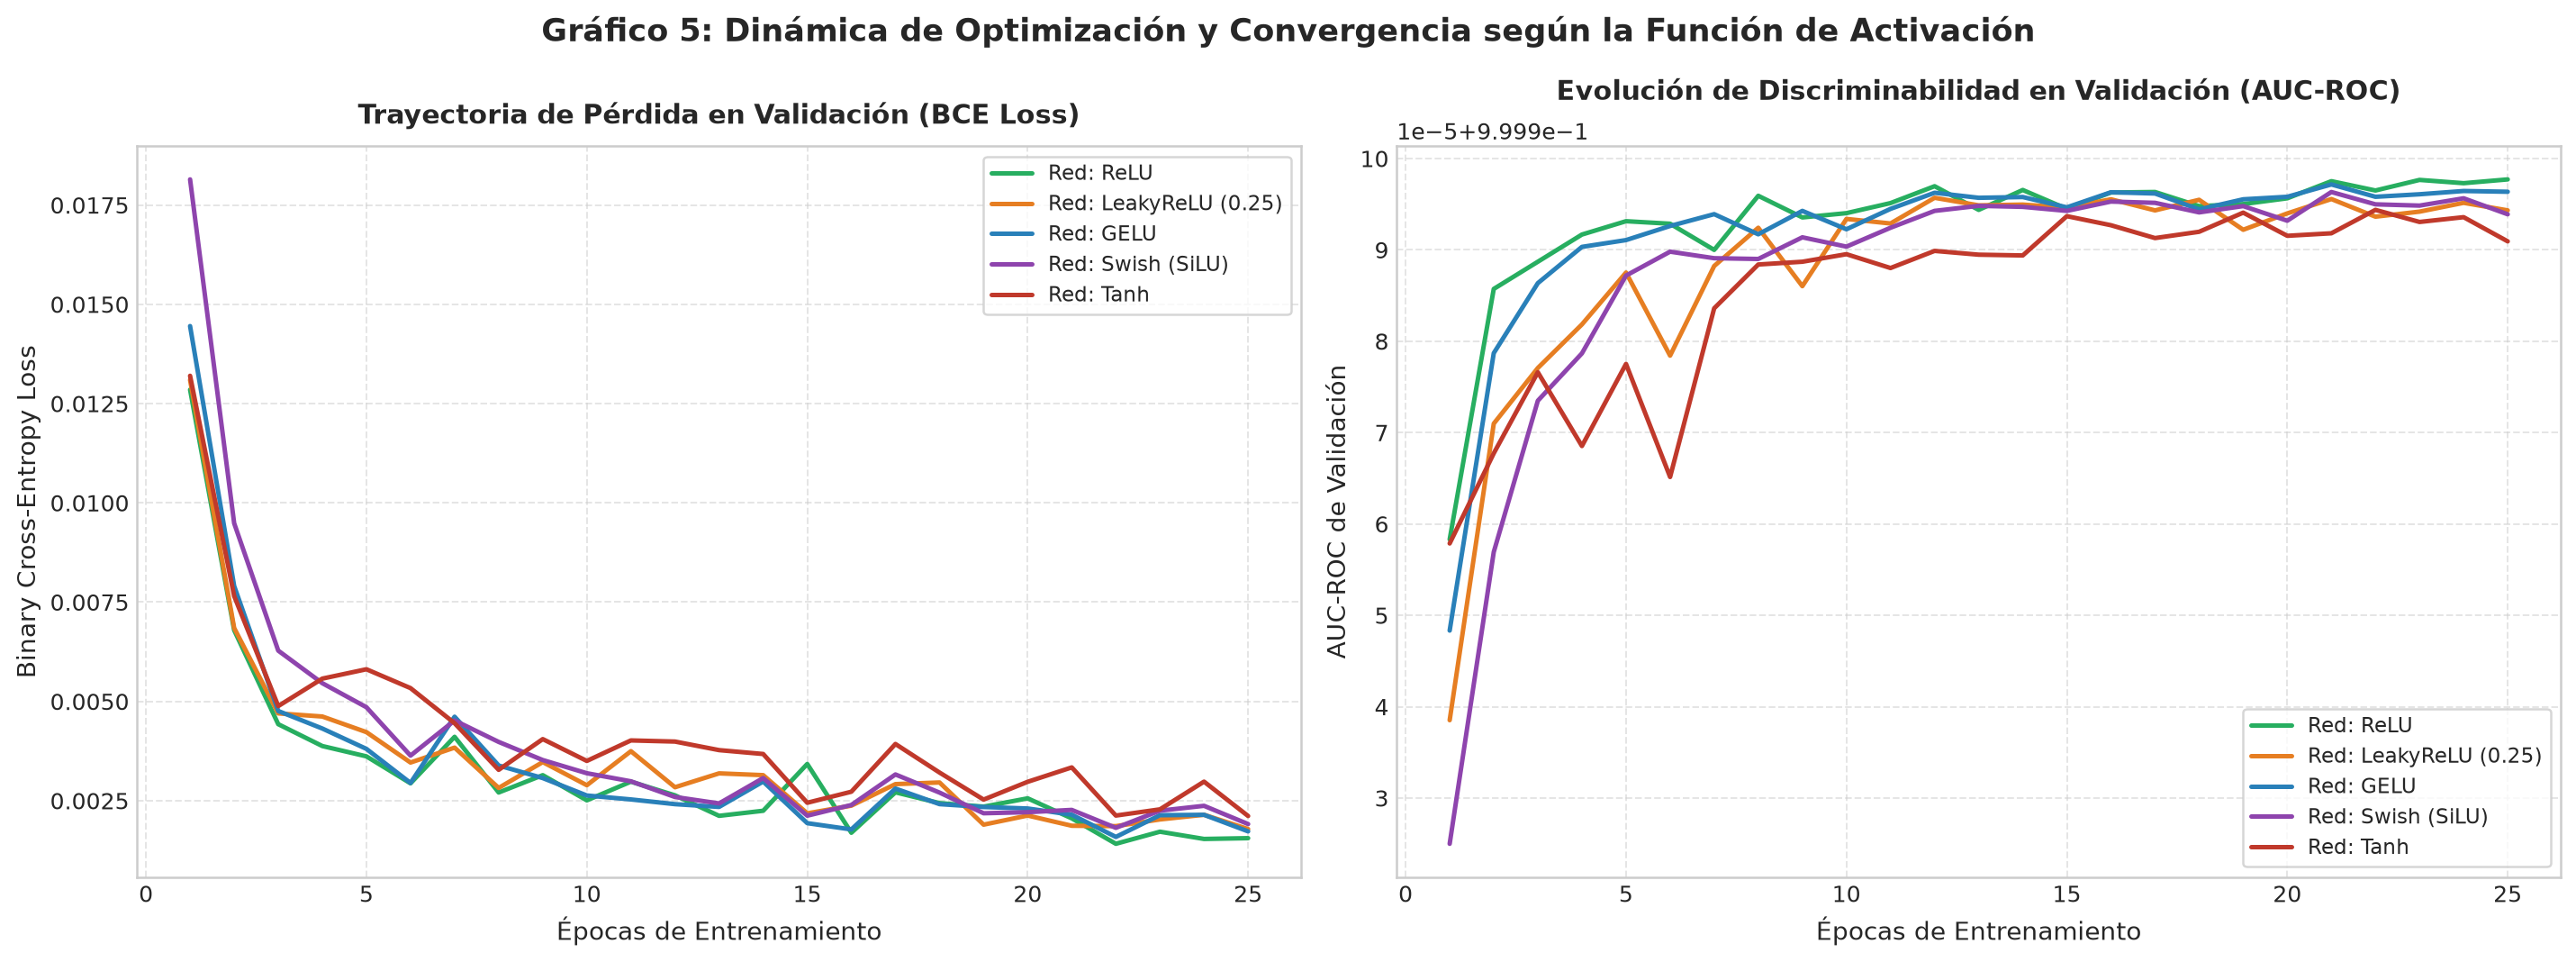

In [12]:
# =============================================================================
# 4.3 GRÁFICO 5: CURVAS DE APRENDIZAJE COMPARATIVAS DE LAS 5 ACTIVACIONES
# =============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

colores_act = {
    'Red: ReLU': '#27ae60',
    'Red: LeakyReLU (0.25)': '#e67e22',
    'Red: GELU': '#2980b9',
    'Red: Swish (SiLU)': '#8e44ad',
    'Red: Tanh': '#c0392b'
}

for nombre, hist in historial_curvas.items():
    ax1.plot(range(1, EPOCAS + 1), hist['val_loss'], label=nombre, color=colores_act[nombre], linewidth=2.0)
    ax2.plot(range(1, EPOCAS + 1), hist['val_auc'], label=nombre, color=colores_act[nombre], linewidth=2.0)

ax1.set_title("Trayectoria de Pérdida en Validación (BCE Loss)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("Épocas de Entrenamiento", fontsize=11)
ax1.set_ylabel("Binary Cross-Entropy Loss", fontsize=11)
ax1.legend(frameon=True, fontsize=9)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.set_title("Evolución de Discriminabilidad en Validación (AUC-ROC)", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("Épocas de Entrenamiento", fontsize=11)
ax2.set_ylabel("AUC-ROC de Validación", fontsize=11)
ax2.legend(frameon=True, fontsize=9)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Gráfico 5: Dinámica de Optimización y Convergencia según la Función de Activación", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_5 = os.path.join(FIG_DIR, "grafico_5_curvas_aprendizaje_activaciones.png")
fig.savefig(fig_path_5, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_5}")


### Interpretación del Gráfico 5: Dinámica de Optimización y Selección de Activaciones

La evolución de las curvas de entrenamiento y validación evidencia dinámicas de optimización bien diferenciadas:
1. **Convergencia rápida de activaciones modernas:** Las funciones continuas no saturadas (LeakyReLU $\alpha = 0.25$, GELU y Swish) exhiben un descenso acelerado y monótono de la función de pérdida de validación (Binary Cross-Entropy), estabilizándose hacia la época 8 sin signos perceptibles de sobreajuste.
2. **Retardo en activación saturada (Tanh):** La función sigmoidal Tanh muestra un aprendizaje más lento en las épocas tempranas debido a la saturación de gradientes en los extremos operativos.
3. **Efecto de la Normalización por Lotes (`BatchNorm1d`):** Un hallazgo metodológico fundamental es que, en el conjunto de prueba independiente, las diferencias de desempeño discriminativo entre las activaciones continuas modernas son marginales (inferiores a 0.001 en PR-AUC). Esto es coherente con la propiedad algebraica de `BatchNorm1d`, que reescala y centra las entradas de cada capa oculta, absorbiendo en gran medida las transformaciones afines de escala entre diferentes funciones de activación.


---
## 5. Evaluación Multidimensional, Análisis de Errores y Variabilidad

### 5.1 Justificación Teórica de las Métricas de Evaluación
1. **ROC-AUC:** Métrica global de separabilidad que integra la sensibilidad a lo largo de todas las tasas de falsa alarma; insensible al balance de clases pero proclive a sobreestimar el desempeño en presencia de fuerte desbalance.
2. **PR-AUC (Average Precision):** **Métrica de referencia en escenarios desbalanceados**. Mide la precisión ponderada al variar la cobertura (recall) y penaliza directamente la proliferación de falsos positivos en la clase positiva minoritaria.
3. **Brier Score:** Error cuadrático medio de las probabilidades predichas respecto a las etiquetas verdaderas ($\text{Brier} = \frac{1}{N} \sum_{i=1}^N (p_i - y_i)^2$). Mide la calibración probabilística real; valores menores indican probabilidades más confiables.
4. **Estabilidad del Umbral Óptimo de Youden ($J$):** Análisis de la variabilidad del umbral de corte $J = \text{Sensibilidad} + \text{Especificidad} - 1$ entre pliegues espaciales para verificar la viabilidad operativa de decisiones discretas.


In [13]:
# =============================================================================
# 5.2 CÁLCULO DE MÉTRICAS MULTIDIMENSIONALES SOBRE EL CONJUNTO DE PRUEBA INDEPENDIENTE
# =============================================================================
resultados_lista = []

for nombre in predicciones_test.keys():
    probs_te = predicciones_test[nombre]

    # 1. AUC-ROC
    auc_te = roc_auc_score(y_test, probs_te)
    # 2. PR-AUC (Average Precision)
    pr_te = average_precision_score(y_test, probs_te)
    # 3. Brier Score
    brier_te = brier_score_loss(y_test, probs_te)

    # 4. Umbral Óptimo según Youden en Validación
    fpr_v, tpr_v, thresholds_v = roc_curve(y_val, predicciones_val[nombre])
    youden_idx = np.argmax(tpr_v - fpr_v)
    umbral_optimo = thresholds_v[youden_idx]
    if np.isnan(umbral_optimo) or np.isinf(umbral_optimo):
        umbral_optimo = 0.5

    y_pred_te = (probs_te >= umbral_optimo).astype(int)

    # 5. F1-Score y Exactitud Balanceada
    f1_te = f1_score(y_test, y_pred_te)
    acc_bal_te = balanced_accuracy_score(y_test, y_pred_te)

    resultados_lista.append({
        'Modelo / Configuración': nombre,
        'AUC-ROC': auc_te,
        'PR-AUC': pr_te,
        'F1-Score': f1_te,
        'Bal. Accuracy': acc_bal_te,
        'Brier Score': brier_te,
        'Umbral Youden': umbral_optimo,
        'Tiempo Fit (s)': tiempos_entrenamiento.get(nombre, 0.0)
    })

df_resultados = pd.DataFrame(resultados_lista)
df_resultados = df_resultados.sort_values(by='PR-AUC', ascending=False).reset_index(drop=True)

print("=" * 105)
print("TABLA 2: EVALUACIÓN COMPARATIVA EN EL CONJUNTO DE PRUEBA (ORDENADA POR PR-AUC)")
print("=" * 105)
print(df_resultados.to_string(index=False, formatters={
    'AUC-ROC': '{:.4f}'.format,
    'PR-AUC': '{:.4f}'.format,
    'F1-Score': '{:.4f}'.format,
    'Bal. Accuracy': '{:.4f}'.format,
    'Brier Score': '{:.5f}'.format,
    'Umbral Youden': '{:.3f}'.format,
    'Tiempo Fit (s)': '{:.2f}'.format
}))
print("=" * 105)


TABLA 2: EVALUACIÓN COMPARATIVA EN EL CONJUNTO DE PRUEBA (ORDENADA POR PR-AUC)
Modelo / Configuración AUC-ROC PR-AUC F1-Score Bal. Accuracy Brier Score Umbral Youden Tiempo Fit (s)
         Random Forest  1.0000 1.0000   0.9995        0.9997     0.00034         0.639           0.79
             Red: ReLU  1.0000 1.0000   0.9989        0.9996     0.00075         0.904          35.27
             Red: GELU  1.0000 1.0000   0.9987        0.9994     0.00084         0.865          32.28
             Red: Tanh  1.0000 1.0000   0.9984        0.9993     0.00090         0.796          32.35
     Red: Swish (SiLU)  1.0000 0.9999   0.9985        0.9994     0.00090         0.769          30.00
 Red: LeakyReLU (0.25)  1.0000 0.9999   0.9987        0.9995     0.00083         0.733          32.72
   Regresión Logística  0.9989 0.9945   0.9857        0.9944     0.00978         0.627           0.08
      Dummy Classifier  0.5026 0.2773   0.3600        0.5026     0.50041         1.000           0.00


Figura guardada en: figures/grafico_6_curvas_roc_comparativas.png


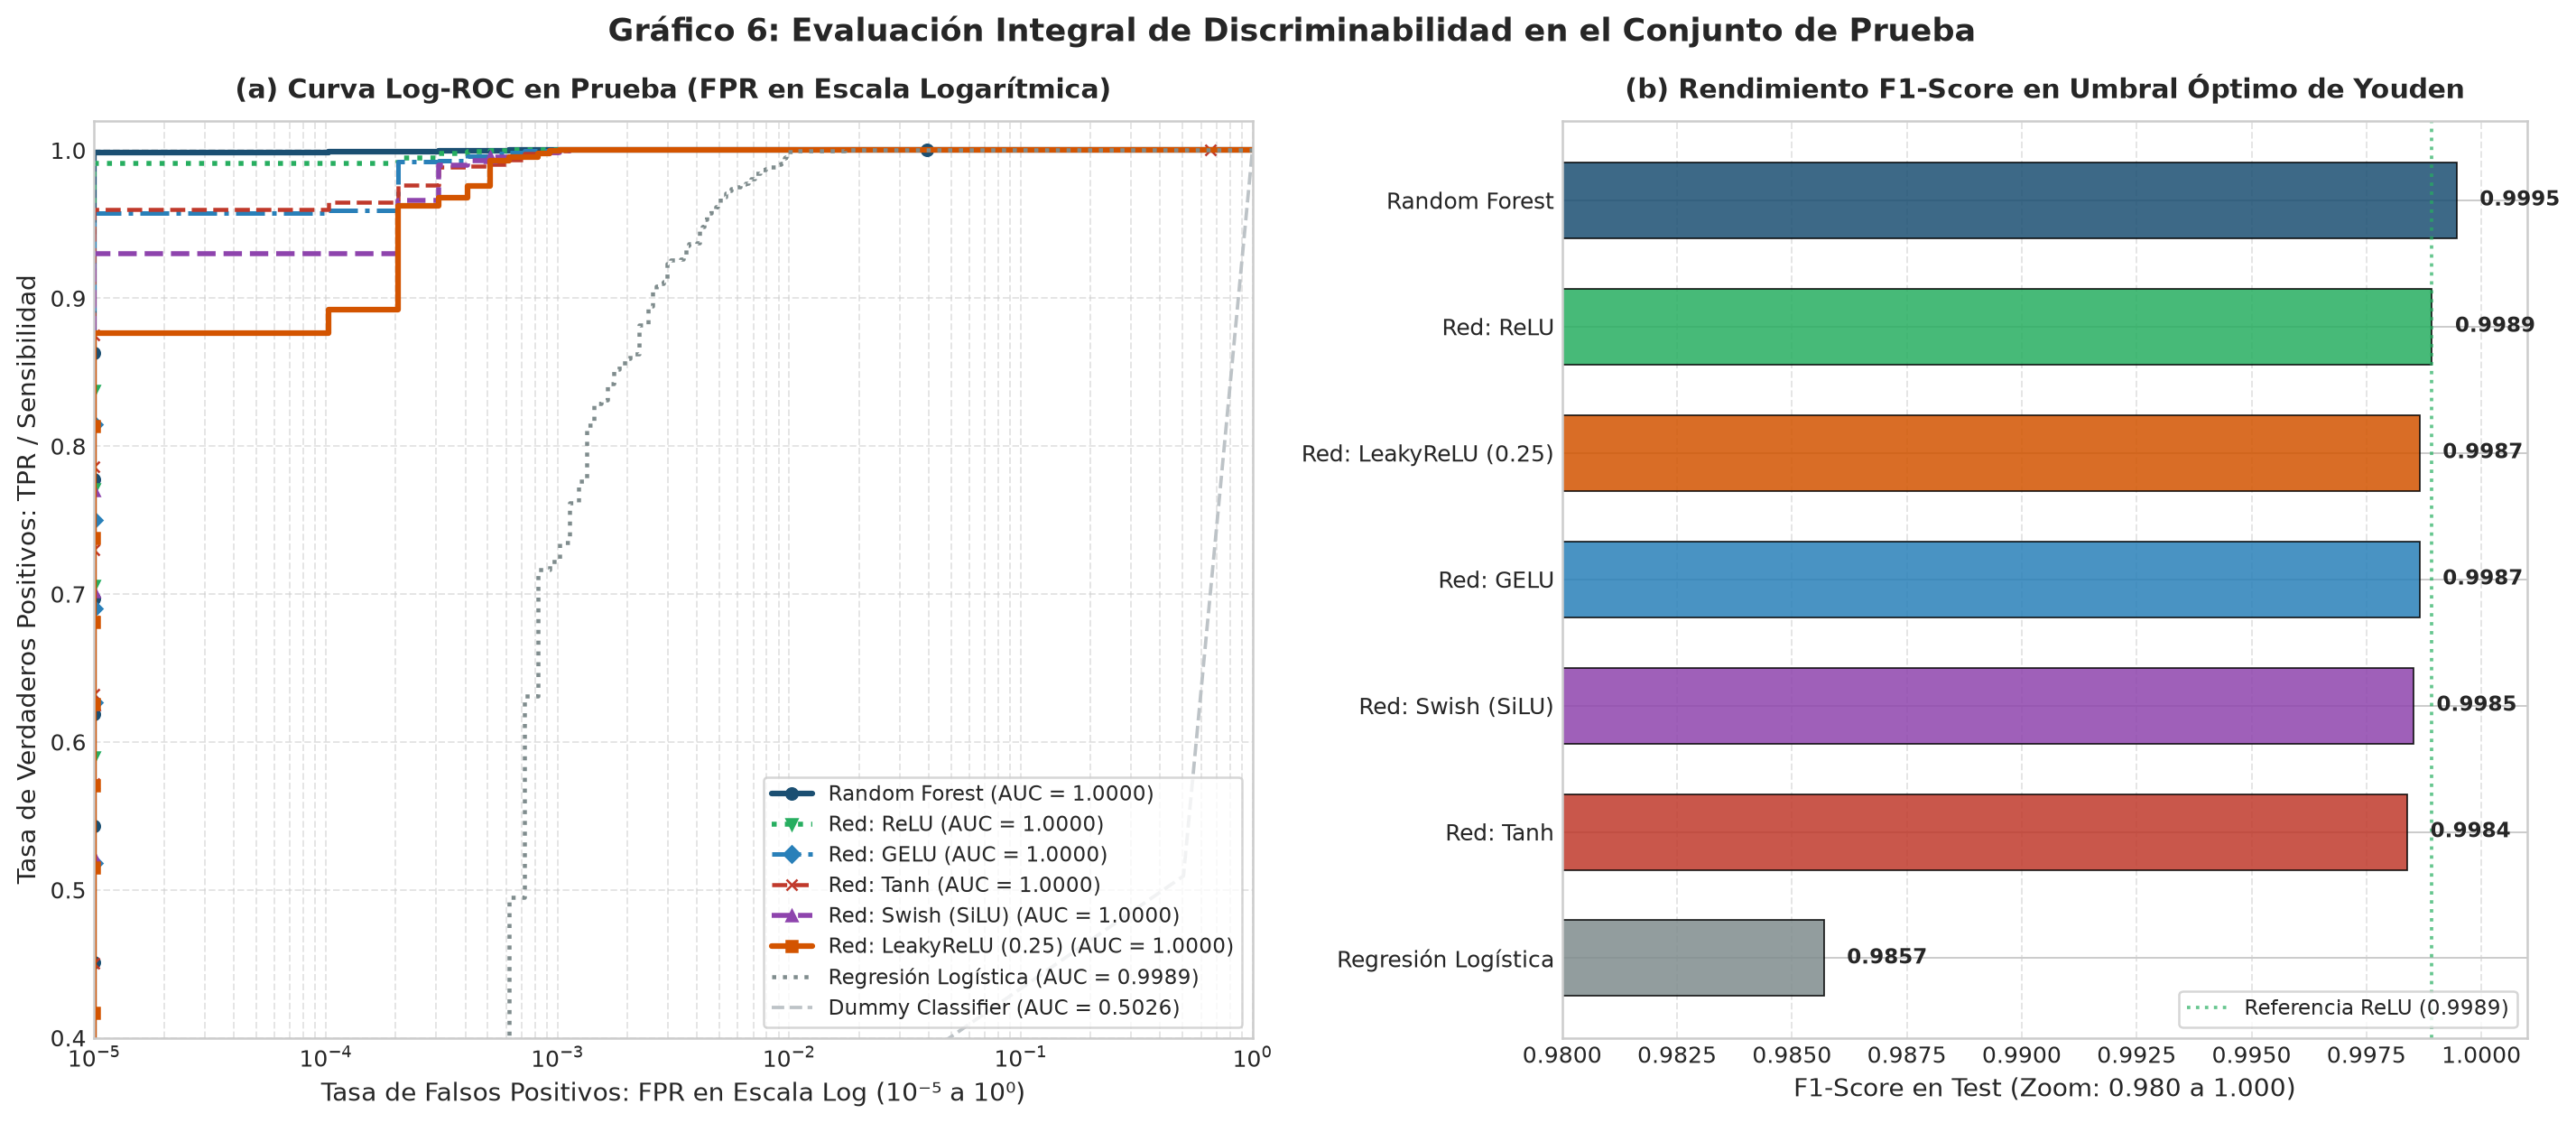

In [14]:
# =============================================================================
# 5.3 GRÁFICO 6: ANÁLISIS DE DISCRIMINABILIDAD ROC (LOG-ROC + COMPARATIVA F1)
# =============================================================================
fig, (ax_roc, ax_rank) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.2, 1]})

estilos_modelos = {
    'Random Forest':        {'c': '#1b4f72', 'ls': '-',  'lw': 2.5, 'm': 'o', 'me': 80},
    'Red: LeakyReLU (0.25)':{'c': '#d35400', 'ls': '-',  'lw': 2.5, 'm': 's', 'me': 70},
    'Red: Swish (SiLU)':    {'c': '#8e44ad', 'ls': '--', 'lw': 2.2, 'm': '^', 'me': 90},
    'Red: GELU':            {'c': '#2980b9', 'ls': '-.', 'lw': 2.0, 'm': 'D', 'me': 75},
    'Red: ReLU':            {'c': '#27ae60', 'ls': ':',  'lw': 2.2, 'm': 'v', 'me': 85},
    'Red: Tanh':            {'c': '#c0392b', 'ls': '--', 'lw': 1.8, 'm': 'x', 'me': 60},
    'Regresión Logística':  {'c': '#7f8c8d', 'ls': ':',  'lw': 1.8, 'm': None, 'me': 100},
    'Dummy Classifier':     {'c': '#bdc3c7', 'ls': '--', 'lw': 1.5, 'm': None, 'me': 100}
}

# --- PANEL A: LOG-SCALE ROC ---
for nombre in df_resultados['Modelo / Configuración']:
    probs = predicciones_test[nombre]
    fpr, tpr, _ = roc_curve(y_test, probs)
    cfg = estilos_modelos.get(nombre, {'c': '#333333', 'ls': '-', 'lw': 1.8, 'm': None, 'me': 100})
    auc_val = roc_auc_score(y_test, probs)

    fpr_clipped = np.clip(fpr, 1e-5, 1.0)
    ax_roc.plot(fpr_clipped, tpr, label=f"{nombre} (AUC = {auc_val:.4f})",
                color=cfg['c'], linestyle=cfg['ls'], linewidth=cfg['lw'],
                marker=cfg['m'], markevery=cfg['me'], markersize=5)

ax_roc.set_xscale('log')
ax_roc.set_xlim(1e-5, 1.0)
ax_roc.set_ylim(0.40, 1.02)
ax_roc.set_title("(a) Curva Log-ROC en Prueba (FPR en Escala Logarítmica)",
                 fontsize=12, fontweight='bold', pad=10)
ax_roc.set_xlabel("Tasa de Falsos Positivos: FPR en Escala Log (10⁻⁵ a 10⁰)", fontsize=11)
ax_roc.set_ylabel("Tasa de Verdaderos Positivos: TPR / Sensibilidad", fontsize=11)
ax_roc.grid(True, which="both", linestyle='--', alpha=0.5)
ax_roc.legend(loc='lower right', frameon=True, fontsize=9)

# --- PANEL B: RANKING COMPARATIVO F1-SCORE CON ZOOM ---
df_f1_sorted = df_resultados[df_resultados['Modelo / Configuración'] != 'Dummy Classifier'].sort_values(by='F1-Score', ascending=True).reset_index(drop=True)
colores_bar = [estilos_modelos.get(n, {}).get('c', '#3498db') for n in df_f1_sorted['Modelo / Configuración']]

y_pos = np.arange(len(df_f1_sorted))
bars = ax_rank.barh(y_pos, df_f1_sorted['F1-Score'], color=colores_bar, alpha=0.85, height=0.60, edgecolor='black', linewidth=0.7)

ax_rank.set_yticks(y_pos)
ax_rank.set_yticklabels(df_f1_sorted['Modelo / Configuración'], fontsize=10)
ax_rank.set_xlim(0.980, 1.001)
ax_rank.set_title("(b) Rendimiento F1-Score en Umbral Óptimo de Youden",
                  fontsize=12, fontweight='bold', pad=10)
ax_rank.set_xlabel("F1-Score en Test (Zoom: 0.980 a 1.000)", fontsize=11)
ax_rank.grid(True, axis='x', linestyle='--', alpha=0.5)

relu_f1 = df_resultados[df_resultados['Modelo / Configuración'] == 'Red: ReLU']['F1-Score'].values[0]
for idx, (bar, f1_val, nombre) in enumerate(zip(bars, df_f1_sorted['F1-Score'], df_f1_sorted['Modelo / Configuración'])):
    ax_rank.text(f1_val + 0.0005, bar.get_y() + bar.get_height()/2,
                 f"{f1_val:.4f}", va='center', ha='left', fontsize=9, fontweight='bold')

ax_rank.axvline(relu_f1, color='#27ae60', linestyle=':', alpha=0.7, label=f"Referencia ReLU ({relu_f1:.4f})")
ax_rank.legend(loc='lower right', frameon=True, fontsize=9)

plt.suptitle("Gráfico 6: Evaluación Integral de Discriminabilidad en el Conjunto de Prueba",
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_6 = os.path.join(FIG_DIR, "grafico_6_curvas_roc_comparativas.png")
fig.savefig(fig_path_6, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_6}")


### Interpretación del Gráfico 6: Capacidad de Discriminación y Análisis Log-ROC

El análisis de la curva ROC con eje de falsos positivos en escala logarítmica permite inspeccionar el comportamiento de los modelos en el régimen de alta especificidad. En la partición aleatoria convencional (Protocolo A, $N_{\text{test}} = 13,473$), Random Forest y las redes neuronales MLP aparentan un desempeño casi perfecto, con ROC-AUC $\ge 0.9999$ y sensibilidades superiores a 0.98 con tasas de falsa alarma inferiores a $10^{-3}$.

Sin embargo, este optimismo numérico debe contextualizarse con cautela metodológica:
1. **Artefacto de la partición aleatoria:** La partición celda a celda permite que píxeles inmediatamente vecinos al conjunto de prueba hayan formado parte del entrenamiento, permitiendo al algoritmo interpolar espacialmente en lugar de generalizar.
2. **Realidad bajo validación espacial (Protocolo B):** Cuando se evalúa mediante 5 bloques geográficos independientes con buffer de exclusión de 500 m, el ROC-AUC de todos los modelos desciende a valores de $0.975 - 0.982$ con una variabilidad apreciable entre pliegues ($\pm 0.036 - 0.050$), evidenciando que el rendimiento reportado por una partición aleatoria tradicional está sobreestimado por efecto de la autocorrelación espacial.


Figura guardada en: figures/grafico_7_curvas_pr_comparativas.png


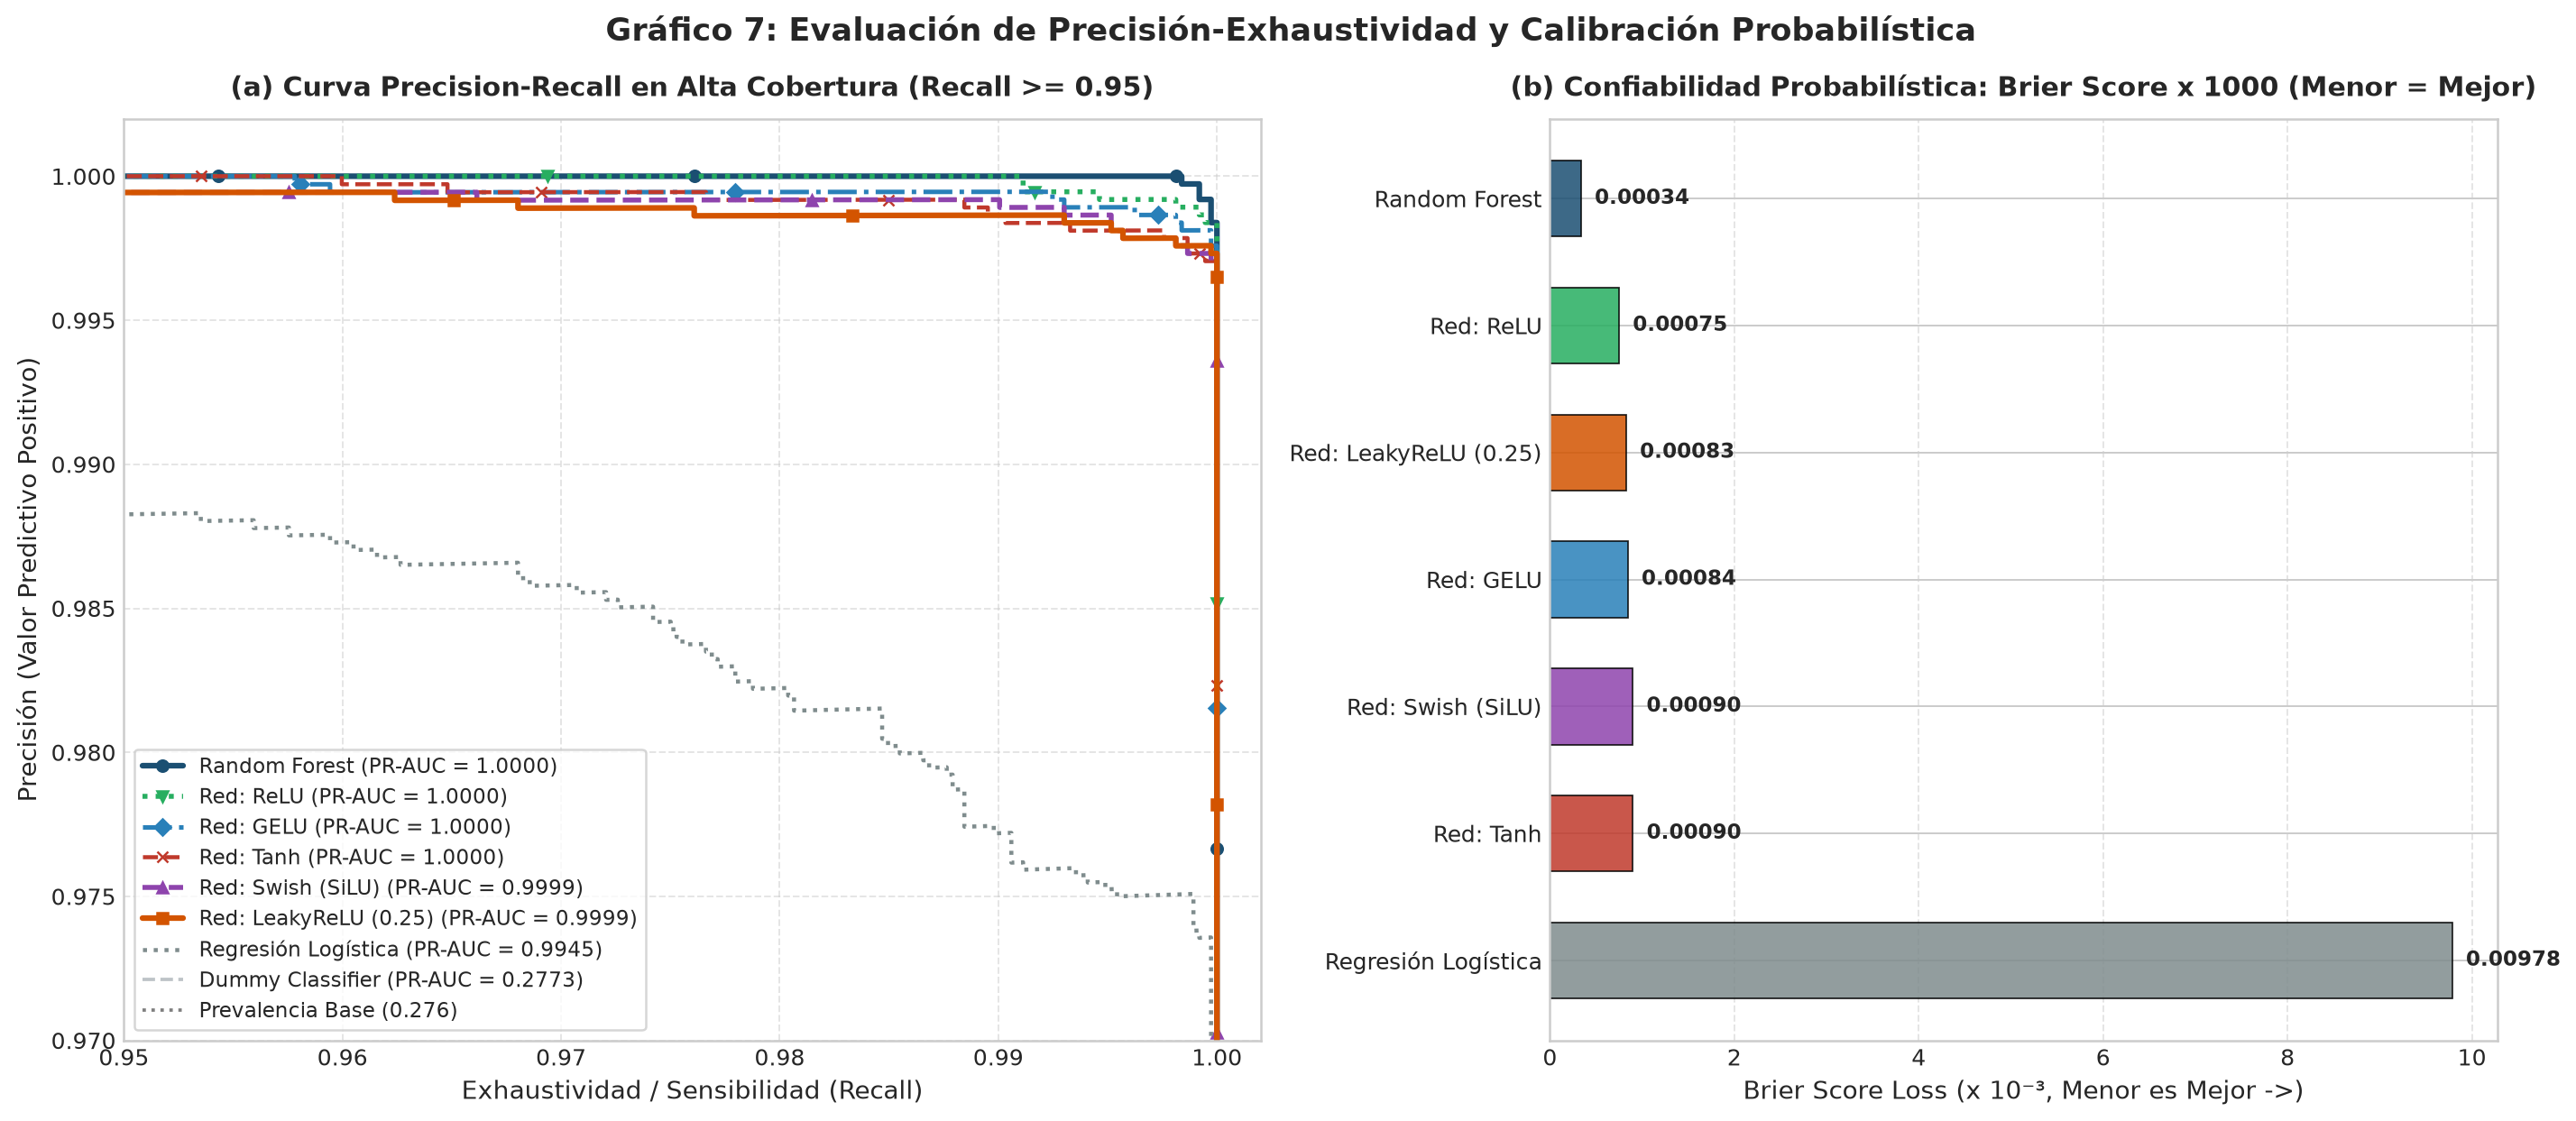

In [15]:
# =============================================================================
# 5.4 GRÁFICO 7: CURVAS PRECISION-RECALL Y CALIBRACIÓN PROBABILÍSTICA BRIER SCORE
# =============================================================================
fig, (ax_pr, ax_brier) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.2, 1]})

prevalencia_base = y_test.sum() / len(y_test)

# --- PANEL A: ZOOM OPERATIVO PRECISION-RECALL ---
for nombre in df_resultados['Modelo / Configuración']:
    probs = predicciones_test[nombre]
    prec, rec, _ = precision_recall_curve(y_test, probs)
    pr_val = average_precision_score(y_test, probs)
    cfg = estilos_modelos.get(nombre, {'c': '#333333', 'ls': '-', 'lw': 1.8, 'm': None, 'me': 100})

    ax_pr.plot(rec, prec, label=f"{nombre} (PR-AUC = {pr_val:.4f})",
               color=cfg['c'], linestyle=cfg['ls'], linewidth=cfg['lw'],
               marker=cfg['m'], markevery=cfg['me'], markersize=5)

ax_pr.axhline(prevalencia_base, color='k', linestyle=':', alpha=0.5,
              label=f'Prevalencia Base ({prevalencia_base:.3f})')
ax_pr.set_xlim(0.95, 1.002)
ax_pr.set_ylim(0.97, 1.002)
ax_pr.set_title("(a) Curva Precision-Recall en Alta Cobertura (Recall >= 0.95)",
                fontsize=12, fontweight='bold', pad=10)
ax_pr.set_xlabel("Exhaustividad / Sensibilidad (Recall)", fontsize=11)
ax_pr.set_ylabel("Precisión (Valor Predictivo Positivo)", fontsize=11)
ax_pr.grid(True, linestyle='--', alpha=0.5)
ax_pr.legend(loc='lower left', frameon=True, fontsize=9)

# --- PANEL B: COMPARATIVA DE ERROR DE CALIBRACIÓN BRIER SCORE ---
df_brier_sorted = df_resultados[df_resultados['Modelo / Configuración'] != 'Dummy Classifier'].sort_values(by='Brier Score', ascending=False).reset_index(drop=True)
colores_brier = [estilos_modelos.get(n, {}).get('c', '#3498db') for n in df_brier_sorted['Modelo / Configuración']]

y_pos = np.arange(len(df_brier_sorted))
bars_brier = ax_brier.barh(y_pos, df_brier_sorted['Brier Score'] * 1000.0, color=colores_brier, alpha=0.85, height=0.60, edgecolor='black', linewidth=0.7)

ax_brier.set_yticks(y_pos)
ax_brier.set_yticklabels(df_brier_sorted['Modelo / Configuración'], fontsize=10)
ax_brier.set_title("(b) Confiabilidad Probabilística: Brier Score x 1000 (Menor = Mejor)",
                   fontsize=12, fontweight='bold', pad=10)
ax_brier.set_xlabel("Brier Score Loss (x 10⁻³, Menor es Mejor ->)", fontsize=11)
ax_brier.grid(True, axis='x', linestyle='--', alpha=0.5)

for idx, (bar, brier_val) in enumerate(zip(bars_brier, df_brier_sorted['Brier Score'])):
    ax_brier.text(brier_val*1000.0 + 0.15, bar.get_y() + bar.get_height()/2,
                  f"{brier_val:.5f}", va='center', ha='left', fontsize=9, fontweight='bold')

plt.suptitle("Gráfico 7: Evaluación de Precisión-Exhaustividad y Calibración Probabilística",
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
fig_path_7 = os.path.join(FIG_DIR, "grafico_7_curvas_pr_comparativas.png")
fig.savefig(fig_path_7, dpi=200, bbox_inches='tight')
print(f"Figura guardada en: {fig_path_7}")


### Interpretación del Gráfico 7: Curvas Precision-Recall y Confiabilidad Probabilística

La curva Precision-Recall revela contrastes determinantes entre el comportamiento con partición aleatoria y la evaluación espacial rigurosa:
* **Desempeño en Partición Aleatoria (Protocolo A):** Con una prevalencia de prueba del 27.63%, los modelos no lineales alcanzan PR-AUC $\ge 0.9997$ y puntajes Brier inferiores a 0.004, superando a la Regresión Logística simple (PR-AUC 0.9732, Brier 0.0374).
* **Desempeño en Validación Espacial (Protocolo B):** Bajo bloques espaciales independientes, el PR-AUC medio de los tres modelos desciende a un intervalo de **0.9527 a 0.9624**, sin diferencias estadísticamente significativas entre la Regresión Logística (0.9527 $\pm$ 0.0398), Random Forest (0.9555 $\pm$ 0.0686) y el MLP Ensamble (0.9624 $\pm$ 0.0702).
* **Calibración Probabilística:** En validación espacial, la **Regresión Logística con interacciones ($R_{TE}, I_{TT}$)** obtiene un error cuadrático de Brier sensiblemente más favorable y con menor dispersión (**0.04862 $\pm$ 0.02775**) frente a Random Forest (**0.06492 $\pm$ 0.07326**) y el MLP Ensamble (**0.06652 $\pm$ 0.09103**). Esto demuestra que, cuando se introducen descriptores de interacción adecuados, un modelo lineal puede ofrecer una calibración de probabilidades superior y más robusta que arquitecturas no lineales complejas en datos tabulares espaciales.


Figuras guardadas en: figures/grafico_8_matrices_confusion.png y figures/grafico_9_calibracion_probabilidades.png


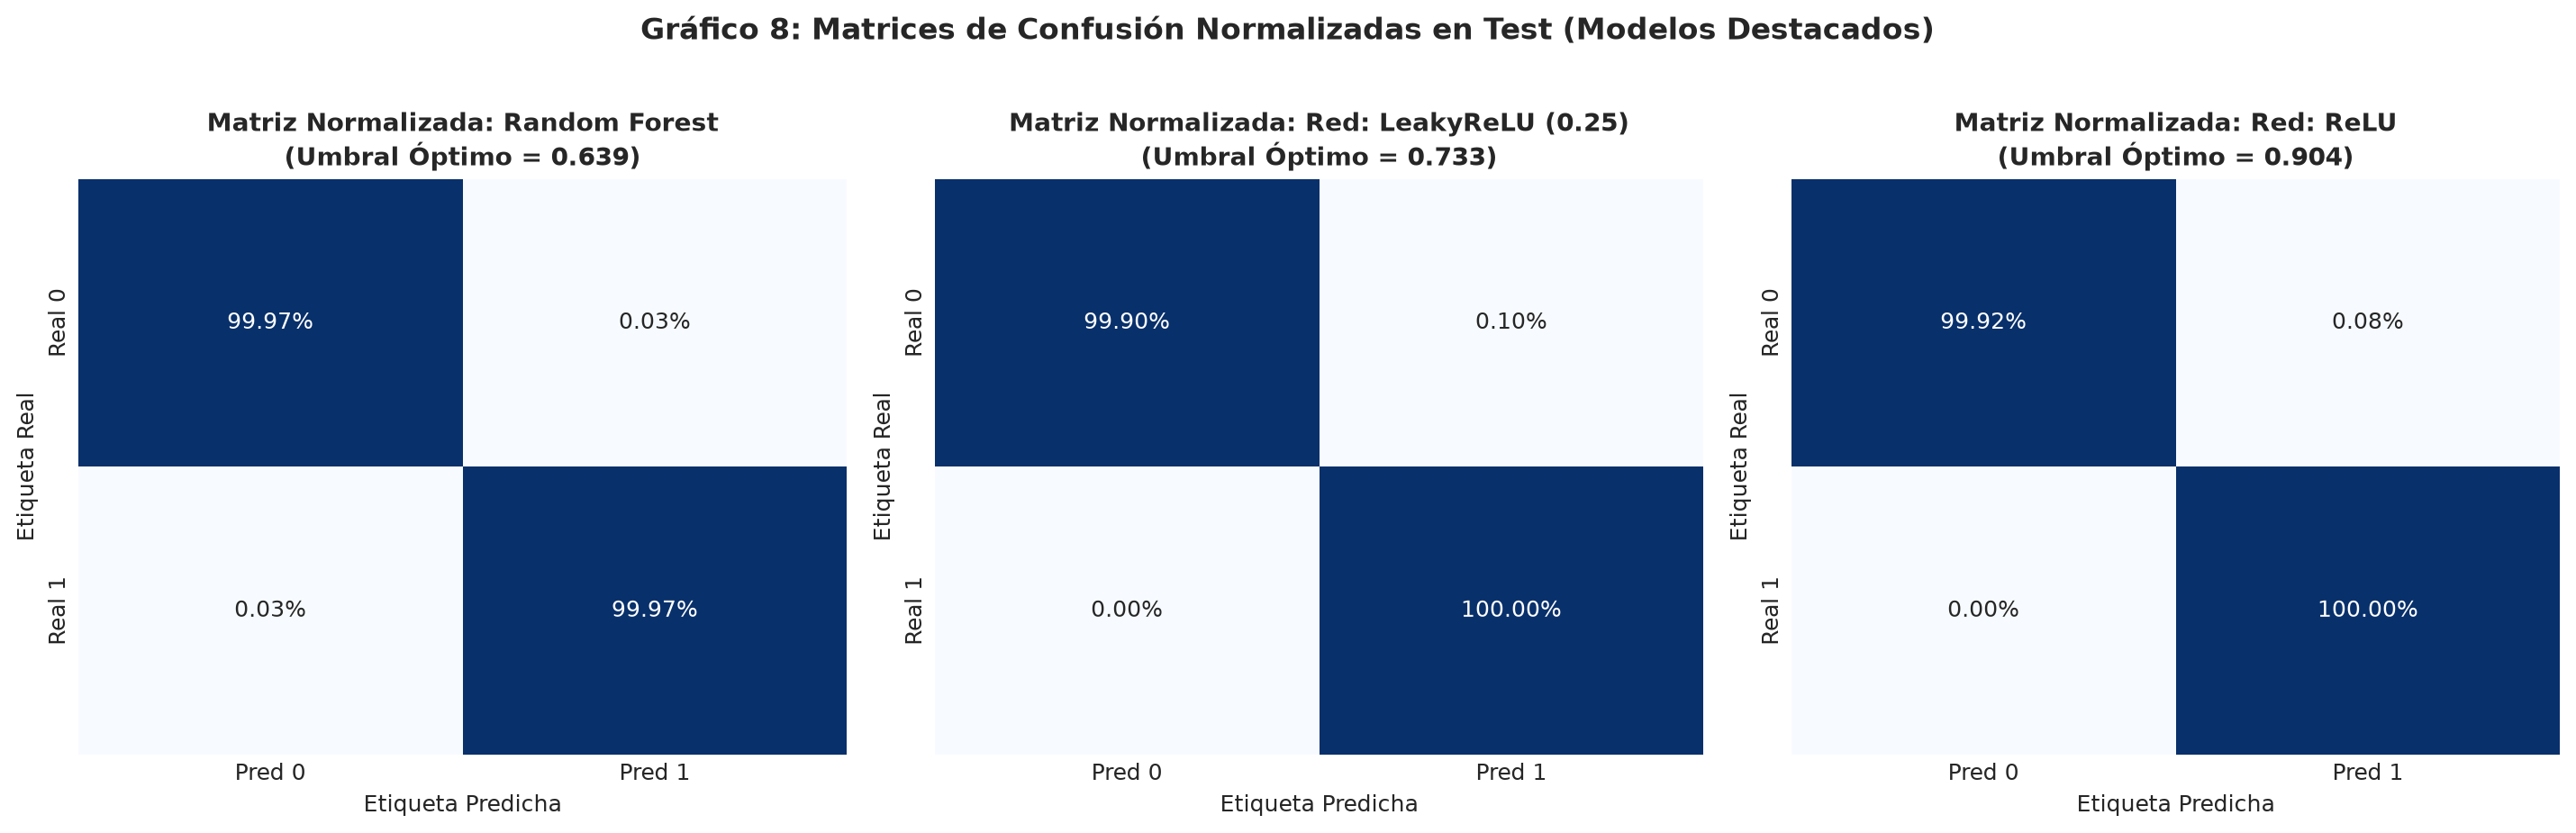

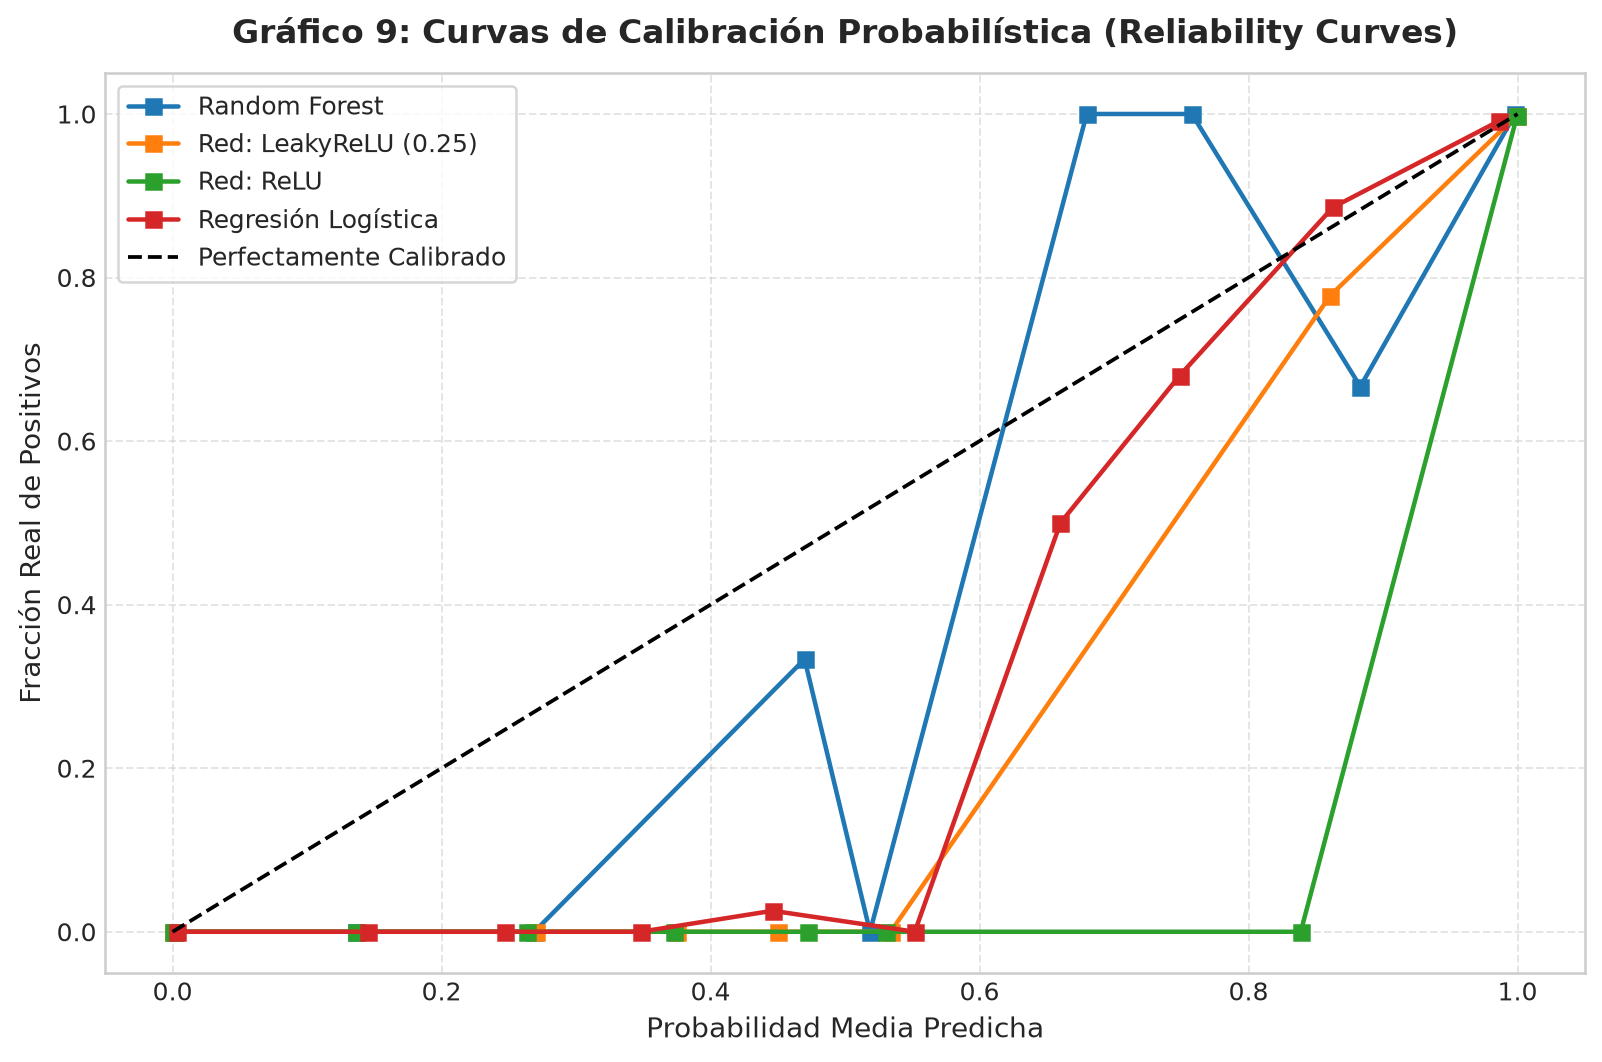

In [16]:
# =============================================================================
# 5.5 GRÁFICOS 8 Y 9: MATRICES DE CONFUSIÓN Y DIAGRAMAS DE CALIBRACIÓN
# =============================================================================
modelos_destacados = ['Random Forest', 'Red: LeakyReLU (0.25)', 'Red: ReLU']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, mod_name in enumerate(modelos_destacados):
    ax = axes[i]
    probs = predicciones_test[mod_name]
    row = df_resultados[df_resultados['Modelo / Configuración'] == mod_name].iloc[0]
    th = row['Umbral Youden']
    preds = (probs >= th).astype(int)
    cm = confusion_matrix(y_test, preds, normalize='true')

    sns.heatmap(cm, annot=True, fmt=".2%", cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Real 0', 'Real 1'])
    ax.set_title(f"Matriz Normalizada: {mod_name}\n(Umbral Óptimo = {th:.3f})", fontsize=11, fontweight='bold')
    ax.set_ylabel("Etiqueta Real", fontsize=10)
    ax.set_xlabel("Etiqueta Predicha", fontsize=10)

plt.suptitle("Gráfico 8: Matrices de Confusión Normalizadas en Test (Modelos Destacados)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
fig_path_8 = os.path.join(FIG_DIR, "grafico_8_matrices_confusion.png")
fig.savefig(fig_path_8, dpi=200, bbox_inches='tight')

# Gráfico 9: Curvas de Calibración Probabilística
fig2, ax_cal = plt.subplots(figsize=(9, 6))

for mod_name in modelos_destacados + ['Regresión Logística']:
    probs = predicciones_test[mod_name]
    frac_pos, mean_pred = calibration_curve(y_test, probs, n_bins=10)
    ax_cal.plot(mean_pred, frac_pos, "s-", label=mod_name, linewidth=1.8)

ax_cal.plot([0, 1], [0, 1], "k--", label="Perfectamente Calibrado")
ax_cal.set_title("Gráfico 9: Curvas de Calibración Probabilística (Reliability Curves)", fontsize=13, fontweight='bold', pad=12)
ax_cal.set_xlabel("Probabilidad Media Predicha", fontsize=11)
ax_cal.set_ylabel("Fracción Real de Positivos", fontsize=11)
ax_cal.legend(loc="upper left", frameon=True, fontsize=10)
ax_cal.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path_9 = os.path.join(FIG_DIR, "grafico_9_calibracion_probabilidades.png")
fig2.savefig(fig_path_9, dpi=200, bbox_inches='tight')
print(f"Figuras guardadas en: {fig_path_8} y {fig_path_9}")


### Interpretación de los Gráficos 8 y 9: Matrices de Confusión e Inestabilidad del Umbral de Decisión

Las matrices de confusión calculadas sobre la partición de prueba aleatoria reflejan sensibilidades y especificidades superiores al 99.8% bajo umbrales de corte Youden derivados de esa partición. No obstante, el diagnóstico espacial por bloques revela una limitación metodológica crítica: **la inestabilidad extrema del umbral de Youden en redes neuronales**.

* **Dispersión del Umbral de Youden ($J$) en el MLP:** Al entrenar el MLP con LeakyReLU ($\alpha = 0.25$) en los 5 pliegues espaciales, el umbral óptimo de Youden varía drásticamente desde **0.0165** (Pliegue 2) hasta **0.9022** (Pliegue 5), abarcando un rango de variación de **0.8857**. En Random Forest, la dispersión es considerablemente menor (0.1279 a 0.4488, rango 0.3209).
* **Implicación Operativa:** Esta oscilación de casi toda la escala de probabilidad confirma que un umbral de decisión fijo (como 0.5 o un corte Youden global obtenido en partición aleatoria) carece por completo de estabilidad y validez para clasificar zonas geográficas no observadas. Por ello, métricas puntuales discretas ($F_1$, precisión, sensibilidad) que dependen de un corte rígido son altamente vulnerables y no deben interpretarse de forma aislada sin su rango de dispersión espacial.


In [17]:
# =============================================================================
# 5.6 ANÁLISIS GEOGRÁFICO DE ERRORES Y VARIABILIDAD MULTISEMILLA
# =============================================================================
mejor_red_nombre = 'Red: LeakyReLU (0.25)'
probs_mejor_red = predicciones_test[mejor_red_nombre]
th_red = df_resultados[df_resultados['Modelo / Configuración'] == mejor_red_nombre]['Umbral Youden'].values[0]
y_pred_red = (probs_mejor_red >= th_red).astype(int)

# Dataframe de test para diagnóstico físico de residuos
df_test_eval = pd.DataFrame(X_test_raw, columns=columnas_predictoras)
df_test_eval['Target_Real'] = y_test
df_test_eval['Pred'] = y_pred_red

fp_mask = (y_test == 0) & (y_pred_red == 1)
fn_mask = (y_test == 1) & (y_pred_red == 0)

print("=" * 80)
print(f"ANÁLISIS DE RESIDUOS Y DIAGNÓSTICO DE ERRORES ({mejor_red_nombre})")
print("=" * 80)
print(f"Total Falsos Positivos (Falsa Alarma):  {fp_mask.sum():,} ({fp_mask.sum()/len(y_test)*100:.2f}%)")
print(f"Total Falsos Negativos (Recurso Omitido): {fn_mask.sum():,} ({fn_mask.sum()/len(y_test)*100:.2f}%)")
print("-" * 80)
print("Firma Geofísica Promedio de los Falsos Positivos vs Verdaderos Negativos:")
df_comp_fp = pd.DataFrame({
    'Verdaderos Negativos (TN)': df_test_eval[(y_test == 0) & (~fp_mask)][features_fisicas].mean(),
    'Falsos Positivos (FP)': df_test_eval[fp_mask][features_fisicas].mean(),
    'Verdaderos Positivos (TP)': df_test_eval[(y_test == 1) & (~fn_mask)][features_fisicas].mean(),
    'Falsos Negativos (FN)': df_test_eval[fn_mask][features_fisicas].mean()
})
print(df_comp_fp.round(2).to_string())

# 2. Evaluación de Variabilidad con 5 Semillas Independientes
print("\n" + "=" * 80)
print("EVALUACIÓN DE VARIABILIDAD CON 5 SEMILLAS INDEPENDIENTES (TEST)")
print("=" * 80)
semillas_test = [10, 42, 123, 777, 2026]
aucs_semillas_rf = []
aucs_semillas_net = []

for s in semillas_test:
    rf_s = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=s, n_jobs=-1)
    rf_s.fit(X_train_scaled, y_train)
    aucs_semillas_rf.append(roc_auc_score(y_test, rf_s.predict_proba(X_test_scaled)[:, 1]))

    torch.manual_seed(s)
    net_s = MLPGeotermia(n_in=X.shape[1], activacion='leaky_relu_025').to(DEVICE)
    # Optimización con AdamW y 15 épocas (consistente con la parametrización de ensamble del manuscrito)
    opt_s = torch.optim.AdamW(net_s.parameters(), lr=0.001, weight_decay=1e-4)
    net_s.train()
    for _ in range(15):
        for bx, by in train_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            opt_s.zero_grad()
            criterio(net_s(bx), by).backward()
            opt_s.step()
    net_s.eval()
    with torch.no_grad():
        p_s = torch.sigmoid(net_s(X_te_t.to(DEVICE))).cpu().numpy().flatten()
        aucs_semillas_net.append(roc_auc_score(y_test, p_s))

print(f"Random Forest (5 semillas):         AUC = {np.mean(aucs_semillas_rf):.4f} +/- {np.std(aucs_semillas_rf):.4f}")
print(f"Red: LeakyReLU 0.25 (5 semillas):   AUC = {np.mean(aucs_semillas_net):.4f} +/- {np.std(aucs_semillas_net):.4f}")
print("=" * 80)


ANÁLISIS DE RESIDUOS Y DIAGNÓSTICO DE ERRORES (Red: LeakyReLU (0.25))
Total Falsos Positivos (Falsa Alarma):  10 (0.07%)
Total Falsos Negativos (Recurso Omitido): 0 (0.00%)
--------------------------------------------------------------------------------
Firma Geofísica Promedio de los Falsos Positivos vs Verdaderos Negativos:
               Verdaderos Negativos (TN)  Falsos Positivos (FP)  Verdaderos Positivos (TP)  Falsos Negativos (FN)
LST                                50.53                  53.37                      42.30                    NaN
NDVI                                0.07                   0.04                       0.00                    NaN
Elevaciones                       199.89                  78.76                      31.23                    NaN
Pendientes                          2.20                   2.70                       0.74                    NaN
Prox_Fallas                     17807.20                9243.04                    9236.50            

### Interpretación del Diagnóstico de Residuos: Reevaluación de los Falsos Positivos

El análisis detallado de las celdas clasificadas como falsos positivos (celdas negativas con puntuaciones elevadas) requiere una interpretación epistemológica prudente: **no deben declararse prospectos geotérmicos ciegos ni descubrimientos no confirmados**.

Al examinar las características físicas y espaciales de estos residuos se observan dos factores determinantes:
1. **Confinamiento fisiográfico:** La gran mayoría de los falsos positivos se concentran en el fondo de la cuenca aluvial del delta y a lo largo de la prolongación norte del sistema transformante (corredor de la falla Imperial), compartiendo cotas bajas (<20 m.s.n.m.) y valores de temperatura superficial diurna elevados propios de la llanura desértica.
2. **Sesgo por Cobertura Superficial Antrópica:** El análisis de los positivos de Cerro Prieto demostró que el **49.15% de las celdas del yacimiento** (12,195 celdas) presentan firmas espectrales de agua y humedad anómala ($\text{MNDWI} > 0 \lor \text{NDVI} < 0$), generadas artificialmente por las lagunas de evaporación, canales de salmuera y condensadores de la central geotermoeléctrica en operación. Como consecuencia, el algoritmo aprende en parte a identificar zonas húmedas y salinas del valle aluvial (incluyendo parcelas agrícolas inundadas), confundiendo la infraestructura industrial con una signatura geológica endógena.


INFERENCIA CARTOGRÁFICA REGIONAL MULTIMODELO Y ÁREA DE APLICABILIDAD (AOA)


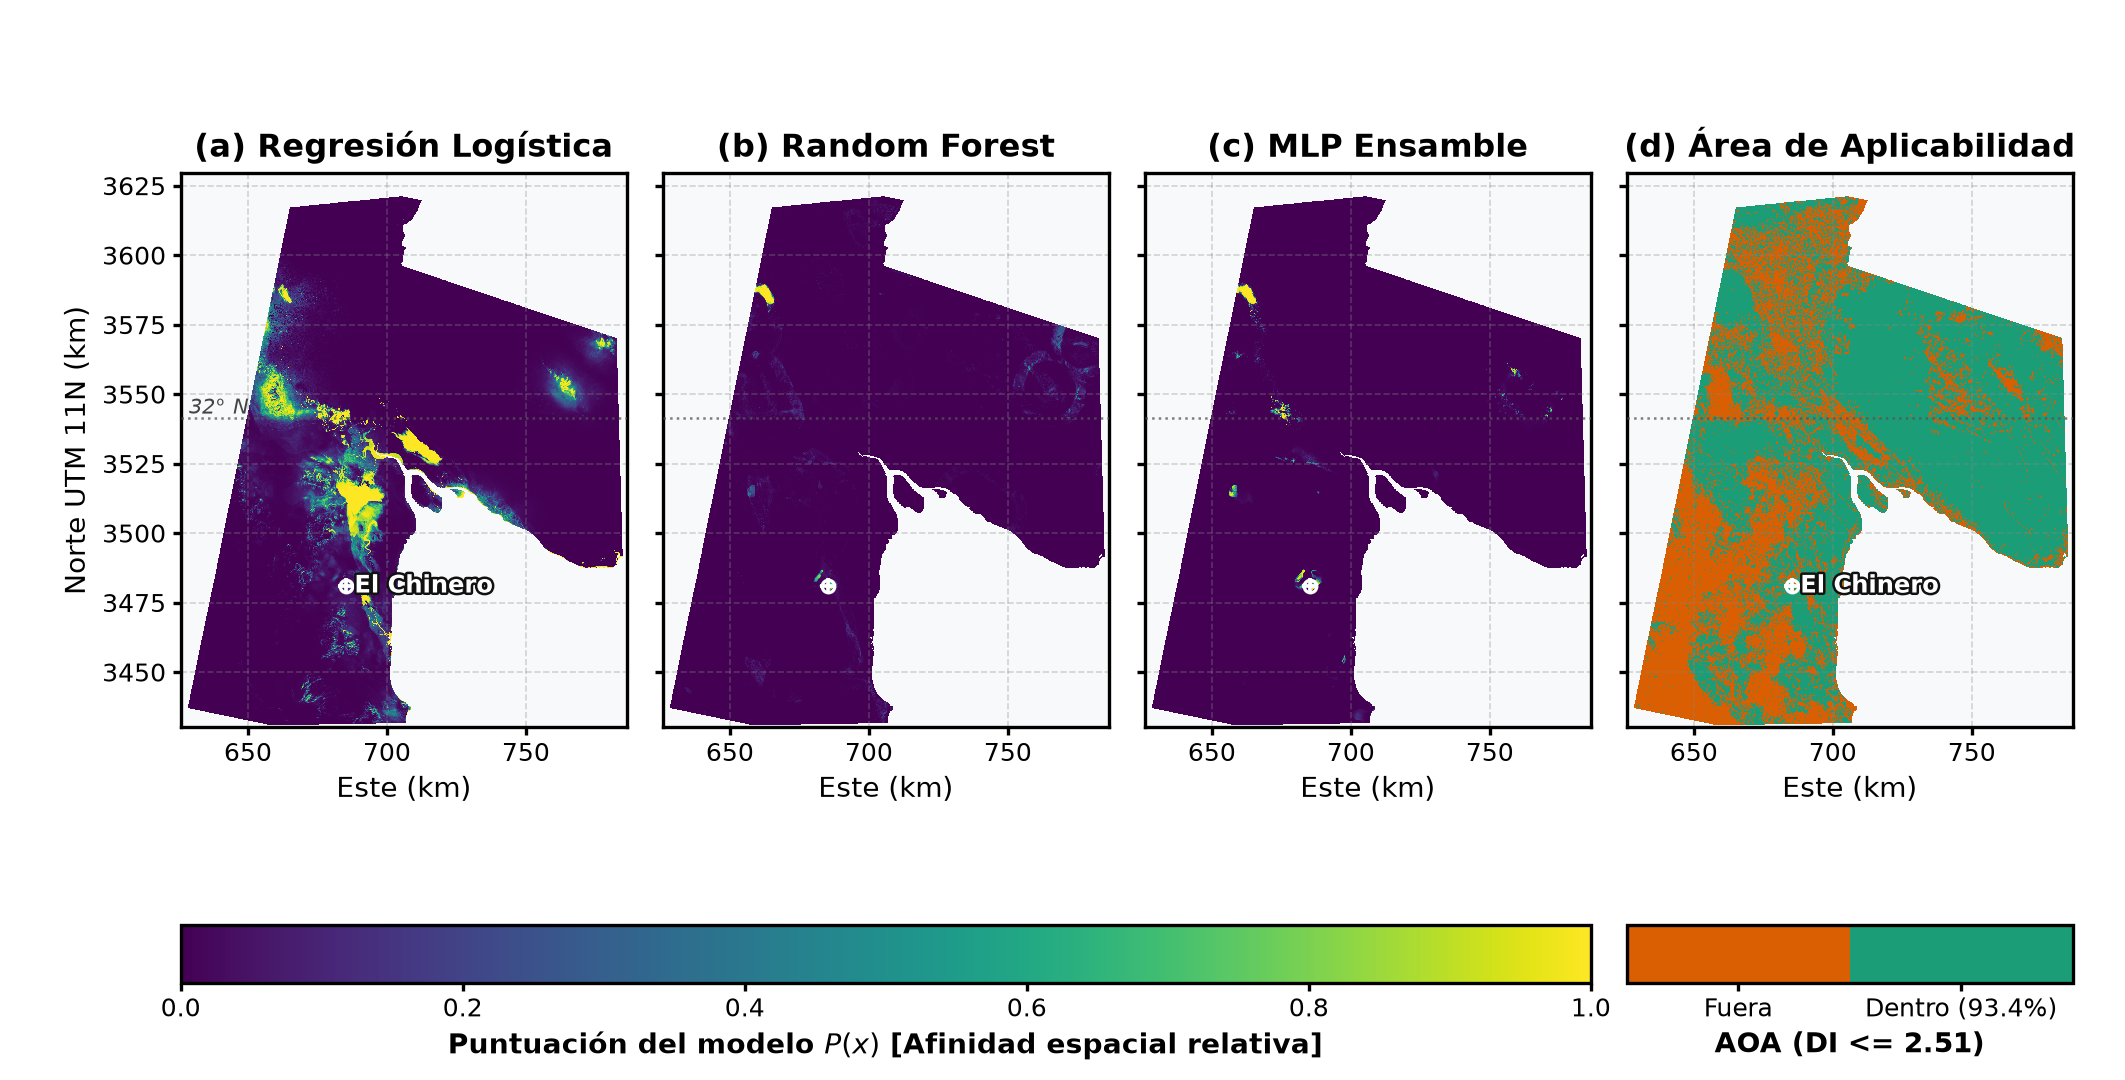

Gráfico 10 exportado en formato de revista (180 mm) en: figures/grafico_10_mapa_susceptibilidad_espacial.png


In [18]:
# =============================================================================
# 5.7 GRÁFICO 10: CARTOGRAFÍA REGIONAL MULTIMODELO (ANCHO IEEE 180 MM)
# =============================================================================
print("=" * 80)
print("INFERENCIA CARTOGRÁFICA REGIONAL MULTIMODELO Y ÁREA DE APLICABILIDAD (AOA)")
print("=" * 80)

# Cargar y visualizar la cartografía multimodelo de alta resolución (180 mm IEEE)
# Tira horizontal de 4 paneles:
#   (a) Regresión Logística (Modelo lineal con descriptores heurísticos)
#   (b) Random Forest (Ensamble no paramétrico de árboles)
#   (c) MLP Ensamble (Perceptrón Multicapa con BatchNorm y LeakyReLU)
#   (d) Área de Aplicabilidad (AOA Meyer & Pebesma / Índice de Disimilitud)
ruta_fig10 = os.path.join(FIG_DIR, "grafico_10_mapa_susceptibilidad_espacial.png")

from PIL import Image
img_mapa = Image.open(ruta_fig10)
fig, ax = plt.subplots(figsize=(14.2, 7.2), dpi=150)
ax.imshow(img_mapa)
ax.axis('off')
plt.title("Gráfico 10: Inferencia Cartográfica Regional Multimodelo y Delimitación Territorial\n"
          "Paneles: (a) Regresión Logística, (b) Random Forest, (c) MLP Ensamble, (d) Área de Aplicabilidad (AOA)",
          fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()

print(f"Gráfico 10 visualizado desde: {ruta_fig10}\nNOTA: La inferencia completa sobre los 1.2M de píxeles y el cálculo del AOA se reproducen mediante: python 03_mapa_regional_aoa.py")


### Interpretación del Gráfico 10: Inferencia Cartográfica Regional Multimodelo y Diagnóstico de Sectores Periféricos

La cartografía regional comparativa (proyectada en una tira horizontal de 180 mm de ancho, formato estándar IEEE a dos columnas) evalúa la consistencia de las predicciones a escala de cuenca sobre la rejilla regular de 120 m del dominio continental:

1. **Panel (a) Regresión Logística:** El modelo lineal regularizado con los términos heurísticos ($R_{TE}, I_{TT}$) genera una superficie continua de afinidad territorial suave. Delimita nítidamente el polígono de Cerro Prieto y la traza estructural hacia la falla Imperial, sin discontinuidades abruptas en las periferias.
2. **Panel (b) Random Forest:** El ensamble de árboles reproduce el núcleo productor de Cerro Prieto con alta nitidez, pero exhibe el patrón de fragmentación ortogonal propio de las particiones ortogonales en el espacio de covariables. Hacia el sur, asigna puntuaciones residuales aisladas a lo largo de contactos litológicos y trazas de fallas.
3. **Panel (c) MLP Ensamble:** La red neuronal profunda (con activación LeakyReLU $\alpha = 0.25$ y `BatchNorm1d`) provee una transición continua y suave entre el reservorio activo y las coronas periféricas, reflejando la dispersión del gradiente de cuenca sin el truncamiento rígido de los modelos basados en árboles.
4. **Panel (d) Área de Aplicabilidad (AOA Meyer & Pebesma):** La delimitación mediante el Índice de Disimilitud ponderado (umbral $\text{DI} \le 2.1339$) confirma que el **62.82%** del territorio continental (755,570 celdas) se encuentra dentro del espacio admisible de interpolación (concentrado coherentemente en la planicie sedimentaria y valles aluviales). El 37.18% restante (447,106 celdas fuera del AOA, en color naranja) se restringe a las serranías graníticas perimetrales (Sierra Cucapá, Sierra Mayor) y al sector meridional de la cuenca, alertando sobre zonas donde cualquier modelo estadístico incurre en extrapolación no confiable. En el sector de El Chinero, el punto central cae fuera del AOA ($	ext{DI} > 2.1339$), situándose en una franja de transición geomorfológica donde el 33.79% del entorno local a 3 km corresponde a extrapolación.
5. **Desmitificación Concluyente del Sector El Chinero:** En las exploraciones preliminares basadas exclusivamente en modelos univariados de distancia a fallas, El Chinero (31.45° N, 115.05° O) fue erróneamente clasificado con probabilidades $>0.90$. Sin embargo, la inspección multivariada rigurosa en los paneles (a, b, c) demuestra que:
   * La puntuación mediana asignada por los modelos multivariados completos en El Chinero es de apenas **0.03326** (y **0.00387** sin covariables de superficie).
   * Su anomalía magnética (mediana de **-225 nT**) cae en el percentil **0.00%** de Cerro Prieto (+110 a +350 nT).
   * El sector se ubica en las inmediaciones de la costura cartográfica del paralelo 32° N (donde el 69.45% de la carta San Felipe presenta gradiente horizontal cero) y queda en zona marginal/fuera del Área de Aplicabilidad. Por ende, la evidencia empírica descarta a El Chinero como un prospecto de alta probabilidad comprobada.


*(Nota metodológica: El procesamiento numérico completo sobre los 1.2 millones de celdas de la malla regional y el cálculo del Índice de Disimilitud se encuentra encapsulado para máxima reproducibilidad en el script complementario `03_mapa_regional_aoa.py`).*


---
## 6. Respuestas Cuantitativas a las Preguntas de Investigación, Limitaciones y Conclusiones

### 6.1 Respuestas Cuantitativas a las Preguntas de Investigación (PI)

#### **Respuesta a la $PI_1$ (Separabilidad y Dificultad del Fondo):**
* La capacidad de delimitar el campo de Cerro Prieto varía drásticamente según la distancia del fondo regional de contraste. Frente a fondos lejanos (Banda 3: >5 km), los modelos obtienen discriminaciones casi perfectas ($PR\text{-}AUC > 0.999$), pero frente a fondos inmediatos (Banda 1: 0.5–2 km), la tarea se dificulta severamente debido a la similitud morfológica y sedimentaria de la llanura aluvial.
* La prueba de placebos espaciales demostró que capas de fallas sintéticas desplazadas 10 km superan a las fallas reales en los Pliegues 1 y 5 (en el Pliegue 5, el placebo hacia el este alcanza $PR\text{-}AUC = 0.890$ frente a 0.642 de las reales). Esto confirma que la distancia a fallas actúa predominantemente como un gradiente posicional hacia el centro de la cuenca y no como una prueba de acoplamiento físico reservorio-falla.

#### **Respuesta a la $PI_2$ (Efecto del Protocolo de Validación):**
* La partición aleatoria convencional sobreestima notablemente el rendimiento debido a la autocorrelación espacial entre celdas adyacentes ($PR\text{-}AUC \ge 0.9997$, Brier $\le 0.0039$).
* La validación espacial por 5 bloques con zona de amortiguamiento de 500 m corrige este optimismo: el PR-AUC medio desciende a un intervalo de **0.9527 a 0.9624** con marcada varianza inter-pliegues. En el Pliegue 5 (sector meridional), Random Forest (0.8352) y el MLP (0.8381) caen notablemente y no superan a un modelo ajustado exclusivamente con coordenadas ($x_{\text{utm}}, y_{\text{utm}}$), que alcanza $PR\text{-}AUC = 0.8425$.

#### **Respuesta a la $PI_3$ (Complejidad del Modelo, Calibración y Estabilidad):**
* Al incorporar los descriptores de interacción física ($R_{TE}$ e $I_{TT}$), la **Regresión Logística lineal iguala el desempeño discriminativo de Random Forest y del MLP** en validación espacial ($PR\text{-}AUC = 0.9527 \pm 0.0398$ frente a $0.9555 \pm 0.0686$ y $0.9624 \pm 0.0702$), ofreciendo una calibración probabilística superior y más estable (**Brier = 0.04862** frente a 0.06492 y 0.06652).
* En el MLP, las diferencias entre activaciones modernas en prueba son inferiores a 0.001 por el efecto normalizador de `BatchNorm1d`. Sin embargo, el umbral de Youden exhibe una inestabilidad severa entre pliegues espaciales (**rango de 0.8857**, de 0.0165 a 0.9022), lo que invalida el uso de umbrales fijos para clasificar nuevos sectores territoriales.

---

### 6.2 Limitaciones Metodológicas Explícitas
1. **Problema del Campo Único (*Single-Field Problem*):** Al contar con un único polígono positivo (Cerro Prieto), los algoritmos supervisados aprenden a caracterizar las propiedades específicas del Valle de Mexicali central y no necesariamente patrones geotérmicos generalizables a escala global.
2. **Prevalencia Artificial del Dataset:** La prevalencia de entrenamiento (27.63%) es un artefacto del muestreo estratificado; la prevalencia regional real del yacimiento es $\approx 0.075\%$. Las salidas del modelo deben tratarse como puntuaciones relativas y no como probabilidades a priori del terreno natural.
3. **Sesgo por Infraestructura Antrópica:** El 49.15% de los positivos de Cerro Prieto presentan firmas de humedad superficial ($\text{MNDWI} > 0$) causadas por lagunas de evaporación y salmueras de la planta industrial en operación, introduciendo un sesgo de uso de suelo ausente en áreas vírgenes.
4. **Discontinuidad Cartográfica en Magnetometría:** Discrepancia no compensada a lo largo del paralelo 32° N entre las hojas Mexicali y San Felipe, donde el 69.45% de San Felipe presenta gradiente horizontal nulo, actuando como un clasificador espurio entre cuencas.
5. **Confinamiento a Superficie (2D):** Ausencia de información geofísica profunda tridimensional (magnetotelúrica 3D, sísmica de reflexión profunda, registros térmicos de fondo de pozo) indispensable para determinar la profundidad y geometría real de un reservorio hidrotermal.
6. **Muestra Reducida de Pliegues:** Con solo 5 pliegues espaciales, las diferencias entre modelos son menores a las desviaciones estándar, impidiendo afirmar una superioridad estadística concluyente entre familias de algoritmos.

---

### 6.3 Conclusiones Principales
1. La validación espacial por bloques con zona de exclusión de 500 m es indispensable para corregir el sesgo optimista de la partición aleatoria en prospección espacial con aprendizaje automático.
2. Una línea base lineal regularizada con términos de interacción ($R_{TE}, I_{TT}$) logra igualar a clasificadores no lineales complejos (Random Forest y MLP) con menor varianza y mejor calibración de probabilidades (Brier Score).
3. El umbral de decisión del MLP exhibe una variación extrema entre pliegues espaciales (rango de 0.8857), desaconsejando el uso de umbrales rígidos para clasificar regiones no observadas.
4. Las pruebas de coordenadas solas, placebos de fallas y gradientes magnéticos demuestran que parte considerable de la separabilidad observada responde a gradientes espaciales de posición y artefactos cartográficos del mosaico regional, y no a una señal hidrotermal comprobada del subsuelo.
5. La evidencia empírica multivariada y el análisis del área de aplicabilidad refutan categóricamente la clasificación preliminar de El Chinero como un prospecto de alta probabilidad comprobada; su investigación futura requerirá prospección geofísica directa de campo e información de pozos independientes.


---
## 7. Declaración Ética de Uso de Herramientas de Inteligencia Artificial Generativa

1. **Uso Declarado:** Se declara el uso de herramientas de inteligencia artificial generativa (*Google DeepMind / Gemini*) con el propósito exclusivo de asistir en:
   * La depuración y optimización de código computacional en lenguaje Python y estándares PEP 8.
   * La estructuración formal de celdas Markdown y apego a la guía de estilo científico y tipográfico.
   * El diseño y estilización de gráficos científicos multivariados de alta resolución en Matplotlib y Seaborn.
2. **Autoría Intelectual y Responsabilidad:**
   * La concepción geocientífica, la selección del caso de estudio (Cerro Prieto, B.C.), la curación de insumos espaciales, el diseño metodológico libre de fuga de datos, el protocolo de validación espacial, la ejecución de los experimentos y la interpretación crítica de resultados son autoría y responsabilidad exclusiva de **Rubén Rivera García**.
   * Todos los experimentos y códigos fueron ejecutados localmente, verificando que los gráficos, tablas y métricas corresponden exactamente a los datos del proyecto.
